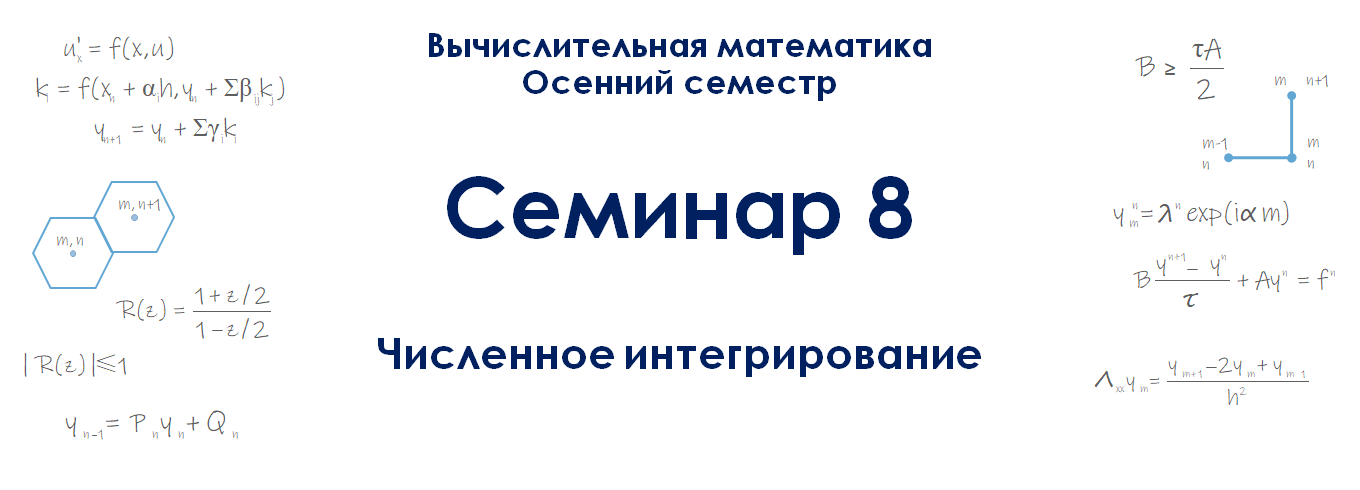

*Версия от 16.10.2026*

*Внимание! Семинар содержит интерактивные демонстрации. На сайте они представлены в статическом виде. Для работы интерактивных элементов необходимо скачать страницу в формате ipynb и запустить ipynb-файл локально.*

Перед изучением материалов семинара рекомендуем посетить лекции или посмотреть их видеозаписи. Ссылки (YouTube): [лекция 11](https://www.youtube.com/live/Kt2tcbBvudA?si=AzjMvzA-LbyRxWkN&t=101) (начало темы), [лекция 12](https://www.youtube.com/live/DcfqfHfYVSQ?si=HuSmTFdR5nRQ2fOW&t=551) (продолжение).

Предполагается, что читатель знает

* определение интерполяционного полинома в форме Лагранжа,

* определение остаточного члена интерполяции $R_n(x)$ и формулу, выражающую его через функцию $\omega_n(x)$,

* алгоритм определения порядка аппроксимации формул численного дифференцирования,

* понятие порядка сходимости численного метода и способ его практического определения (с использованием последовательности сгущающихся сеток).

# Введение

Во многих прикладных задачах возникает необходимость вычислять определённые интегралы вида

$$I=\int\limits_a^b\mathop{dx}f(x).$$

Здесь подынтегральная функция $f=f(x)$, являющаяся скалярной функцией скалярного аргумента, предполагается достаточно гладкой (по крайней мере непрерывной) на отрезке интегрирования $[a,b]$, так что интеграл $I$ существует и в смысле определения Лебега, и в смысле определения Римана. Пределы интегрирования $a$ и $b$, вообще говоря, могут быть как конечными, так и бесконечными (если интеграл понимается в несобственном смысле, то предполагается, что он сходится абсолютно).

В математическом анализе основной вычислительной формулой, применяемой для нахождения интеграла $I$ (в случае конечных $a$ и $b$), служит **формула Ньютона—Лейбница**, согласно которой

$$I=F(b)-F(a),$$

где $F=F(x)$ — первообразная функции $f$ на отрезке $[a,b]$. Однако воспользоваться этой формулой можно лишь тогда, когда первообразную $F$ удаётся выразить в элементарных функциях. К сожалению, на практике подобные случаи почти не встречаются: хорошо известно, что в современных научных задачах подынтегральные функции обычно оказываются настолько "сложными", что соответствующие интегралы "не берутся".

Типичные примеры подобных задач легко найти в курсах обыкновенных дифференциальных уравнений и уравнений в частных производных. Решения многих из этих уравнений (за исключением простейших) **выражаются**, как принято говорить, **в квадратурах**, т.е. имеют вид интегралов от некоторых комбинаций конечного числа элементарных функций. После получения квадратуры обычно считается, что рассматриваемое уравнение решено (конечно, более правильно говорить о решении начальной, краевой или начально-краевой задачи, сформулированной для данного уравнения). Однако сама по себе квадратура, являясь решением уравнения с теоретической точки зрения, ещё не даёт решения в практическом смысле. Чтобы "что-то посчитать" с помощью найденной квадратуры в рамках решения поставленной предметной задачи, надо тем или иным способом вычислить интеграл, входящий в квадратуру. Чем "сложнее" дифференциальное уравнение, тем "сложнее" интеграл, и на практике для его нахождения часто приходится прибегать к численным методам.

Наконец, некоторые дифференциальные уравнения не удаётся решить даже в квадратурах. В подобных случаях решения находят приближённо с помощью численных методов — например, методов Рунге—Кутты для обыкновенных дифференциальных уравнений или конечно-разностных методов для уравнений в частных производных (методы Рунге—Кутты мы будем изучать на одном из следующих семинаров этого семестра). По сути, такой подход тоже представляет собой численное интегрирование: уравнение, которое не удаётся проинтегрировать (решить) аналитически, заменяется своим дискретным аналогом, а поиск решения дискретного аналога "настоящего" уравнения в некотором смысле является численным интегрированием.

Существуют различные подходы к численному нахождению определённых интегралов. Наиболее широкое распространение получили методы, основанные на замене интеграла $I$ конечной суммой

$$\widetilde{I}=\sum\limits_{i=0}^N c_i f(x_i),$$

в которой $c_i$ — некоторые числовые коэффициенты, $x_i$ — точки, принадлежащие отрезку интегрирования $[a,b]$, а $N$ — целое число. Сумма $\widetilde{I}$ называется **квадратурной суммой** (этим как бы подчёркивается, что она заменяет собой квадратуру, т.е. интеграл). Эта сумма строится так, чтобы выполнялось приближённое равенство $I\simeq\widetilde{I}$, называемое **квадратурной формулой**. Коэффициенты $c_i$ называют **весами квадратурной формулы**, а точки $x_i$ — её **узлами**.

Квадратурные формулы можно строить различными способами, из которых мы рассмотрим два наиболее распространённых.

Первый способ основан на следующей идее. Подынтегральная функция $f$ приближается на отрезке $[a,b]$ алгебраическим полиномом $P_n$:

$$I=\int\limits_a^b\mathop{dx}f(x)\simeq\int\limits_a^b\mathop{dx}P_n(x)\equiv \widetilde{I}.$$

Поскольку

$$P_n(x)=\sum\limits_{i=0}^n f(x_i)\cdot\ell_i(x),$$

можно написать:

$$\widetilde{I}=\sum\limits_{i=0}^n c_if(x_i),\quad c_i=\int\limits_a^b\mathop{dx}\ell_i(x).$$

Как видим, при замене функции $f$ на полином $P_n$ действительно получилась квадратурная формула. Она называется **квадратурной формулой интерполяционного типа** (название отражает способ её получения). Далее мы увидим, что в процедуру построения подобных формул следует внести одно небольшое усложнение, заключающееся в предварительном разбиении отрезка интегрирования на несколько подотрезков.

Второй способ построения формул численного интегрирования заключается в специальном подборе весов $c_i$ и узлов $x_i$ с таким расчётом, чтобы приближённое равенство

$$I=\int\limits_a^b\mathop{dx}f(x)\simeq \sum\limits_{i=0}^N c_i f(x_i)=\widetilde{I}$$

становилось точным на полиномах как можно более высокой степени. Формулы, получающиеся на основе этого требования, называются **квадратурными формулами Гаусса** (или Гаусса—Кристоффеля).

Мы начнём с изучения квадратурных формул интерполяционного типа (точнее говоря, рассмотрим один конкретный подвид этих формул). Везде далее в этом семинаре будем предполагать, что оба предела интегрирования $a$ и $b$ конечны, а подынтегральная функция не имеет особенностей на отрезке $[a,b]$ (интеграл рассматривается в собственном смысле).

# Квадратурные формулы Ньютона—Котеса

Как уже отмечалось, квадратурные формулы интерполяционного типа получаются путём замены подынтегральной функции алгебраическим полиномом (т.е. путём интерполяции). Рассмотрим эту процедуру подробно.

## Вывод "простых" формул и оценка их погрешности

Пусть на отрезке $[a,b]$ введена сетка $G_n$ (состоящая из узлов $x_i$, $0\leq i\leq n$); вообще говоря, она может быть и неравномерной. Построим на этой сетке интерполяционный полином $P_n$, приближающий подынтегральную функцию $f$. Из определения остаточного члена интерполяции следует, что

$$f(x)=P_n(x)+R_n(x),\quad x\in[a,b].$$

Подставим в это равенство выражения для интерполяционного полинома $P_n$ (в форме Лагранжа) и остаточного члена $R_n$ (последнее мы получали на семинаре 6 при изучении глобальной интерполяции):

$$f(x)=\sum\limits_{i=0}^nf(x_i)\cdot\ell_i(x)+\frac{f^{(n+1)}(\xi)}{(n+1)!}\cdot\omega_n(x),\quad \xi\in[a,b].$$

Интегрирование этого равенства по отрезку $[a,b]$ даёт:

$$I=\widetilde{I}+\frac{f^{(n+1)}(\xi)}{(n+1)!}\cdot\int\limits_a^b\mathop{dx}\omega_n(x),\quad \widetilde{I}=(b-a)\cdot\sum\limits_{i=0}^nc_if(x_i),\quad c_i=\frac{1}{b-a}\int\limits_a^b\mathop{dx}\ell_i(x)$$

(множитель $(b-a)$ введён в квадратурную сумму $\widetilde{I}$ для удобства дальнейших выкладок). Отсюда следует оценка на ошибку квадратурной формулы (берём точную верхнюю грань по $\xi$):

$$|I-\widetilde{I}|\leq\frac{M_{n+1}}{(n+1)!}\cdot\Bigg|\int\limits_a^b\mathop{dx}\omega_n(x)\Bigg|,\quad M_{n+1}=\sup\limits_{\xi\in[a,b]}\big|f^{(n+1)}(\xi)\big|.$$

Выполним в двух возникших выше интегралах (от $\omega_n$ и $\ell_i$) **линейную** замену переменной

$$x(y)=\frac{a+b}{2}+\frac{b-a}{2}\,y,$$

чтобы перевести отрезок интегрирования $[a,b]$ в отрезок $[-1,1]$ (мы уже рассматривали этот приём на семинаре 6 при изучении глобальной интерполяции). Тогда, как нетрудно видеть,

$$\widetilde{I}=(b-a)\cdot\sum\limits_{i=0}^nc_if(x_i),\quad c_i=\frac{1}{2}\int\limits_{-1}^1\mathop{dy}\ell_i(y);\quad |I-\widetilde{I}|\leq\frac{M_{n+1}}{(n+1)!}\cdot\bigg(\frac{b-a}{2}\bigg)^{n+2}\cdot\Bigg|\int\limits_{-1}^1\mathop{dy}\omega_n(y)\Bigg|.$$

Подчеркнём, что

$$\omega_n(y)=\prod\limits_{i=0}^n(y-y_i),\quad\ell_i(y)=\prod\limits_{\substack{j=0 \\ j\neq i}}^n\frac{y-y_j}{y_i-y_j},$$

т.е. при рассмотрении выписанных выше интегралов не следует забывать, что в результате замены $x=x(y)$ **узлы сетки поменялись**: "новые" узлы $y_i$ принадлежат отрезку $[-1,1]$ и рассчитываются по формуле

$$y_i=\frac{2x_i}{b-a}-\frac{b+a}{b-a},\quad 0\leq i\leq n.$$

С другой стороны, **относительное расположение узлов** на отрезке интегрирования **не изменилось**. Это значит, что если "старая" сетка имела шаги $h_i^{(x)}=x_{i+1}-x_{i}$, а "новая" сетка имеет шаги $h_i^{(y)}=y_{i+1}-y_i$, то

$$\frac{h_{i}^{(x)}}{h_{j}^{(x)}}=\frac{h_{i}^{(y)}}{h_{j}^{(y)}},\quad 0\leq i\neq j\leq n-1.$$

Последнее свойство является следствием линейности замены переменной $x=x(y)$.

Мы ограничимся рассмотрением наиболее простых и распространённых квадратурных формул интерполяционного типа. Именно, будем рассматривать формулы, построенные на **равномерных сетках, у которых граничные узлы совпадают с граничными узлами отрезка интегрирования**. Такие квадратурные формулы называются **формулами Ньютона—Котеса**.

Из сказанного выше следует, что узлам $x_i$ "старой" сетки, введённой на отрезке $[a,b]$ для построения некоторой формулы Ньютона—Котеса, соответствуют узлы

$$y_i=-1+\frac{2}{n}\cdot i\quad (0\leq i\leq n)$$

"новой" сетки на отрезке $[-1,1]$. Поэтому

$$\begin{gather}
  \int\limits_{-1}^1\mathop{dy}\omega_n(y)=\int\limits_{-1}^1\mathop{dy}\prod\limits_{j=0}^n\bigg(y+1-\frac{2}{n}\cdot j\bigg)\equiv \Omega_n,\\
  c_i=\frac{1}{2}\int\limits_{-1}^1\mathop{dy}\prod\limits_{\substack{j=0 \\ j\neq i}}^n\bigg[\frac{n}{2}\cdot \frac{y+1-2/n\cdot j}{i-j}\bigg]\equiv\Omega_n^{(i)}\cdot\frac{n^n}{2^{n+1}}\cdot\prod\limits_{\substack{j=0 \\ j\neq i}}^n\frac{1}{i-j}.
  \end{gather}$$

Отметим, что интеграл, обозначенный здесь через $\Omega_n^{(i)}$, получается из интеграла, обозначенного через $\Omega_n$, отбрасыванием в подынтегральном выражении сомножителя, отвечающего узлу $y_i$.

Таким образом, окончательно квадратурные формулы Ньютона—Котеса принимают следующий вид:

$$I\simeq\widetilde{I}=(b-a)\cdot\frac{n^n}{2^{n+1}}\cdot\sum\limits_{i=0}^n\bigg[f(x_i)\cdot\Omega_n^{(i)}\cdot\prod\limits_{\substack{j=0 \\ j\neq i}}^n\frac{1}{i-j}\bigg],$$

а их погрешность оценивается так:

$$|I-\widetilde{I}|\leq\frac{M_{n+1}\cdot|\Omega_n|}{(n+1)!}\cdot\bigg(\frac{b-a}{2}\bigg)^{n+2}.$$

Повторим, что здесь

$$\Omega_n=\int\limits_{-1}^1\mathop{dy}\prod\limits_{j=0}^n\bigg(y+1-\frac{2}{n}\cdot j\bigg),\quad \Omega_n^{(i)}=\int\limits_{-1}^1\mathop{dy}\prod\limits_{\substack{j=0 \\ j\neq i}}^n\bigg(y+1-\frac{2}{n}\cdot j\bigg).$$

Подчеркнём, что эти величины не зависят от границ отрезка $[a,b]$: они определяются только **относительным** расположением узлов на отрезке интегрирования (а оно в случае формул Ньютона—Котеса полностью задаётся параметром $n$). Отметим также, что интегралы $\Omega_n$ и $\Omega_n^{(i)}$ обладают полезными **свойствами симметрии**, облегчающими построение конкретных формул Ньютона—Котеса:

$$\Omega_{2k}=0,\quad \Omega_{2k}^{(i)}=\Omega_{2k}^{(2k-i)},\quad \Omega_{2k+1}^{(i)}=-\Omega_{2k+1}^{(2k+1-i)}.$$

**Упражнение 1.** Докажите эти свойства.

## Составные формулы

Обратим внимание на следующее обстоятельство. Оценка погрешности квадратурной формулы получилась пропорциональной длине отрезка интегрирования $(b-a)$ в некоторой целой степени (тем большей, чем больше узлов используется для интерполяции подынтегральной функции). Это значит, что **при прочих равных условиях оценка погрешности формулы Ньютона—Котеса на подотрезке $[a',b']\subset[a,b]$ будет ограничена сильнее (точнее, не слабее), чем на всём отрезке**. В самом деле, если отрезок $[a',b']$ вложен в отрезок $[a,b]$, то, разумеется, $b'-a'\leq b-a$; кроме того,

$$\sup\limits_{\xi\in[a',\,b']}\big|f^{(n+1)}(\xi)\big|\leq \sup\limits_{\xi\in[a,\,b]}\big|f^{(n+1)}(\xi)\big|,$$

поскольку, как известно, с увеличением отрезка точная верхняя грань может только увеличиться. Значит, при переходе от "большого" отрезка $[a,b]$ к "маленькому" подотрезку $[a',b']$ константа $M_{n+1}$ не может возрасти.

Это наблюдение наводит на мысль модифицировать построенные формулы Ньютона—Котеса так, чтобы интеграл $I$ "собирался" по "маленьким кусочкам" отрезка $[a,b]$, поскольку погрешности формул на каждом подотрезке ограничены сильнее, чем на всём отрезке (различие в оценках тем значительнее, чем меньше длина подотрезка). Формализуем эту идею.

Разобьём исходный отрезок интегрирования $[a,b]$ на $N$  **частичных отрезков интегрирования** $[z_k,z_{k+1}]$ (вообще говоря, отрезки могут быть разной длины). Такое разбиение эквивалентно введению на отрезке $[a,b]$ сетки

$$z_0=a,\quad z_1,\quad\dots,\quad z_k,\quad\dots,\quad z_N=b$$

с шагами $h_k=z_{k+1}-z_k$ ($0\leq k\leq N-1$), вообще говоря, неравными. Пользуясь аддитивностью интеграла, можем написать:

$$I=\int\limits_a^b\mathop{dx}f(x)=\sum\limits_{k=0}^{N-1}\int\limits_{z_k}^{z_{k+1}}\mathop{dx}f(x)\equiv \sum\limits_{k=0}^{N-1} I_k.$$

Интеграл $I_k$ приближаем уже известной нам квадратурной суммой

$$\widetilde{I}_k=h_k\cdot\frac{n^n}{2^{n+1}}\cdot\sum\limits_{i=0}^n\bigg[f(\widehat{x}_i)\cdot\Omega_n^{(i)}\cdot\prod\limits_{\substack{j=0 \\ j\neq i}}^n\frac{1}{i-j}\bigg].$$

"Шляпка" над обозначением узла $x_i$ подчёркивает, что этот узел должен принадлежать частичному отрезку $[z_k,z_{k+1}]$. Иначе говоря, узлы для интерполяции подынтегральной функции (в количестве $n+1$) должны вводиться на каждом частичном отрезке интегрирования. Можно сказать, что в предлагаемой модификации формул Ньютона—Котеса задействуются как бы **два уровня сеток**. Сетка первого уровня (основная, "крупная") разбивает отрезок интегрирования $[a,b]$ на частичные отрезки интегрирования (подотрезки) и никакого отношения к интерполяции не имеет. Сетки второго уровня ("мелкие") вводятся на каждом частичном отрезке интегрирования, получившемся после построения основной сетки; именно они задействуются в интерполяции. Подчеркнём, что **здесь и далее через $h_k$ мы обозначаем шаги сетки первого уровня** (т.е. длины подотрезков).

В силу построения формул Ньютона—Котеса граничные узлы всех сеток второго уровня совпадают с соответствующими узлами сетки первого уровня, так что общее количество узлов, в которых должны быть заданы значения функции $f$, равно

$$K=(n+1)N-(N-1)=nN+1.$$

Действительно, всего имеем $N$ частичных отрезков интегрирования, на каждом из которых задано $n+1$ узлов для интерполяции. При подсчёте всех этих узлов внутренние узлы основной сетки (в количестве $N-1$) учитываются, очевидно, дважды. Отсюда и следует приведённая формула.

Формулы Ньютона—Котеса, модифицированные путём разбиения отрезка $[a,b]$ на подотрезки $[z_{k},z_{k+1}]$, называются **составными формулами Ньютона—Котеса**.

Погрешность приближения "куска" $I_k$ интеграла $I$ квадратурной суммой $\widetilde{I}_k$ оценивается по выведенной выше формуле:

$$|I_k-\widetilde{I}_k|\leq\frac{|\Omega_n|}{2^{n+2}\cdot(n+1)!}\cdot M^{(k)}_{n+1}h_k^{n+2},\quad M^{(k)}_{n+1}=\sup\limits_{\xi\in[z_{k},\,z_{k+1}]}\big|f^{(n+1)}(\xi)\big|,$$

причём первый множитель в этой оценке одинаков для всех частичных отрезков интегрирования. Значит, погрешность вычисления всего интеграла $I$ по составной формуле есть ("c.f." — "composite formula")

$$|I-\widetilde{I}|^{(\text{c.f.})}=\Bigg|\sum\limits_{k=0}^{N-1}(I_k-\widetilde{I}_k)\Bigg|\leq\sum\limits_{k=0}^{N-1}|I_k-\widetilde{I}_k|\leq \frac{|\Omega_n|}{2^{n+2}\cdot(n+1)!}\cdot\sum\limits_{k=0}^{N-1} M^{(k)}_{n+1}h_k^{n+2}\equiv\Delta^{(\text{c.f.})}.$$

Сравним эту оценку с полученной выше оценкой, справедливой при отсутствии разбиения на частичные отрезки интегрирования (для удобства сравнения выпишем эту оценку ещё раз):

$$|I-\widetilde{I}|\leq \frac{|\Omega_n|}{2^{n+2}\cdot(n+1)!}\cdot M_{n+1}(b-a)^{n+2}\equiv\Delta^{(\text{s.f.})}$$

("s.f." — "simple formula"). Как видим, $\Delta^{(\text{c.f.})}\leq \Delta^{(\text{s.f.})}$, если

$$\sum\limits_{k=0}^{N-1} M^{(k)}_{n+1}h_k^{n+2}\leq M_{n+1}(b-a)^{n+2}.$$

Дадим оценку сверху на сумму, стоящую в левой части этого неравенства. Поскольку подынтегральная функция $f$ может быть произвольной, про величины $M^{(k)}_{n+1}$ в общем случае известно только то, что они не превосходят величины $M_{n+1}$ (в силу упомянутого выше свойства точной верхней грани). Далее, обозначим через $h$ **мелкость основной сетки** (т.е. наибольший из её шагов $h_k$). Тогда

$$\sum\limits_{k=0}^{N-1} M^{(k)}_{n+1}h_k^{n+2}\leq M_{n+1}\cdot\sum\limits_{k=0}^{N-1} h_k^{n+2}\leq M_{n+1} h^{n+1}\cdot\sum\limits_{k=0}^{N-1} h_k=M_{n+1} h^{n+1} (b-a).$$

Значит, если $h^{n+1}\leq (b-a)^{n+1}$, т.е. если $h\leq b-a$, то $\Delta^{(\text{c.f.})}\leq \Delta^{(\text{s.f.})}$ для любой подынтегральной функции $f$. Отсюда и следует, что погрешность составной формулы Ньютона—Котеса ограничена сильнее (точнее, не слабее), чем погрешность "простой" формулы (без разбиения отрезка интегрирования на подотрезки), как и утверждалось. Действительно, уже при двух частичных отрезках интегрирования выполняется неравенство $h<b-a$.

Выполненную только что оценку для суммы, включающей величины $M_{n+1}^{(k)}$, обычно учитывают в оценке погрешности $|I-\widetilde{I}|^{(\text{c.f.})}$, т.е. пишут, что

$$|I-\widetilde{I}|^{(\text{c.f.})}\leq \frac{M_{n+1}\cdot|\Omega_n|}{2^{n+2}\cdot(n+1)!}\cdot h^{n+1} (b-a)\equiv\Delta_n.$$

Именно величиной $\Delta_n$ пользуются при оценке погрешностей конкретных формул Ньютона—Котеса, хотя такая оценка и завышена по сравнению с оценкой через величину $\Delta^{(\text{c.f.})}$.

Итак, мы показали, что **оценка на погрешность составной формулы Ньютона—Котеса ограничена сильнее, чем погрешность той же формулы** (т.е. формулы с тем же $n$) **в "простом" виде** (построенной без разбиения отрезка $[a,b]$ на подотрезки). Поэтому на практике обычно пользуются именно составными формулами. Они обладают и ещё одним преимуществом: оказывается, что **составная формула менее чувствительна к ошибкам округления и входных данных**, т.е. обнаруживает лучшую численную устойчивость (по сравнению с "простой" формулой при том же $n$). Мы не будем доказывать это утверждение.

Из сказанного следует вывод: если нужно проинтегрировать функцию, заданную на отрезке $[a,b]$ в $K$ точках (считая границы отрезка), то нет смысла строить на этом отрезке интерполяционный полином высокой степени $K-1$ и интегрировать его. Вместо этого лучше
*  разбить отрезок $[a,b]$ на $N$ подотрезков,
*  построить на каждом подотрезке интерполяционные полиномы невысокой степени $n$, причём, как мы показали выше, должно иметь место равенство $K=nN+1$,
*  проинтегрировать эти полиномы на каждом подотрезке,
* результаты сложить.

Такой подход даст более точное приближение к искомому интегралу $I$.

## Порядок аппроксимации формул Ньютона—Котеса

Константа $\Delta_n$, являющаяся оценкой сверху на погрешность составной формулы Ньютона—Котеса, пропорциональна величине $h^{n+1}$. Это значит, что при измельчении основной сетки в $q$ раз оценка погрешности численного интегрирования уменьшится в $q^{n+1}$ раз (при прочих равных условиях). В подобных случаях говорят, что формула численного интегрирования имеет $(n+1)$-й **порядок аппроксимации** (ср. с понятием порядка аппроксимации, введённым на первом семинаре при рассмотрении формул численного дифференцирования). Отсюда как будто бы следует, что если на каждом частичном отрезке интегрирования подынтегральная функция заменяется алгебраическим интерполянтом степени $n$, то порядок аппроксимации соответствующей формулы Ньютона—Котеса оказывается равным $n+1$ (совпадает с количеством узлов интерполяции). Однако из этого правила есть исключение.

Как уже отмечалось, $\Omega_{2k}=0$, поэтому и $\Delta_{2k}=0$, т.е. в оценке погрешности составной формулы Ньютона—Котеса **с чётным $n$** обращается в нуль член, пропорциональный $h^{n+1}$. При этом сама погрешность, очевидно, не равна нулю. Дело просто в том, что **при чётном $n$ порядок аппроксимации составной формулы Ньютона—Котеса повышается** и возникает необходимость уточнить оценку погрешности.

Можно показать, что для уточнения оценки достаточно **при расчёте величины $\Delta_n$** увеличить число $n$ на единицу и добавить в подынтегральное выражение интеграла $\Omega_n$ ещё один множитель $y$ (один множитель $y$ уже присутствует, поскольку при чётном $n$ середина отрезка интегрирования обязательно является узлом интерполяции). Другими словами, **если степень интерполяционного полинома $n$ чётна, то надо считать, что центральный узел интерполяции** (в терминах переменной $y$ это нулевой узел) **дублируется, и поэтому его требуется учитывать дважды**. Таким образом, оценка погрешности составной квадратурной формулы Ньютона—Котеса принимает следующий вид:

$$\Delta_{n}'=\frac{M_{n+2}\cdot|\Omega_{n}'|}{2^{n+3}\cdot(n+2)!}\cdot h^{n+2} (b-a),\quad \Omega_{n}'=\int\limits_{-1}^1\mathop{dy}\Bigg[y\cdot\prod\limits_{j=0}^{n}\bigg(y+1-\frac{2}{n}\cdot j\bigg)\Bigg],\quad n=2k.$$

Штрихи при обозначениях $\Delta_{n}$ и $\Omega_{n}$ указывают на то, что эти величины рассчитываются не так, как в случае нечётного $n$.

Ориентируясь на более точную оценку погрешности при $n=2k$, приходим к выводу: **при чётном $n$ порядок аппроксимации составной формулы Ньютона—Котеса равен $n+2$**.

## Сводка общих теоретических сведений

Мы провели общий теоретический анализ формул Ньютона—Котеса. Для удобства справок дадим сводку полученных результатов.

1. Квадратурная формула Ньютона—Котеса имеет следующий вид:

   $$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}\widetilde{I}_k,\quad \widetilde{I}_k=h_k\cdot\frac{n^n}{2^{n+1}}\cdot\sum\limits_{i=0}^n\bigg[f(\widehat{x}_i)\cdot\Omega_n^{(i)}\cdot\prod\limits_{\substack{j=0 \\ j\neq i}}^n\frac{1}{i-j}\bigg],$$

   где $n$ — степень интерполянта, приближающего подынтегральную функцию, $N>0$ — количество частичных отрезков интегрирования (имеющих длины $h_k$), на которые разбит исходный отрезок $[a,b]$ (случай $N=1$ отвечает "простой" формуле, случай $N>1$ — составной); кроме того,

   $$\Omega_n^{(i)}=\int\limits_{-1}^1\mathop{dy}\prod\limits_{\substack{j=0 \\ j\neq i}}^n\bigg(y+1-\frac{2}{n}\cdot j\bigg),\quad\text{причём}\quad \Omega_{2k}^{(i)}=\Omega_{2k}^{(2k-i)},\quad \Omega_{2k+1}^{(i)}=-\Omega_{2k+1}^{(2k+1-i)}.$$

2. **При нечётном $n$** погрешность квадратурной формулы $|I-\widetilde{I}|$ оценивается величиной

   $$\Delta_n=\frac{M_{n+1}\cdot|\Omega_n|}{2^{n+2}\cdot(n+1)!}\cdot h^{n+1} (b-a),$$

   где

   $$\Omega_n=\int\limits_{-1}^1\mathop{dy}\prod\limits_{j=0}^n\bigg(y+1-\frac{2}{n}\cdot j\bigg).$$

   **При чётном** $n$ та же оценка выглядит несколько иначе:

   $$\Delta_n'=\frac{M_{n+2}\cdot|\Omega_n'|}{2^{n+3}\cdot(n+2)!}\cdot h^{n+2} (b-a),$$

   где

   $$\Omega_n'=\int\limits_{-1}^1\mathop{dy}\Bigg[y\cdot\prod\limits_{j=0}^n\bigg(y+1-\frac{2}{n}\cdot j\bigg)\Bigg].$$

   В обеих оценках

   $$M_{n}=\sup\limits_{\xi\in[a,b]}\big|f^{(n)}(\xi)\big|,\qquad h=\max\limits_{k} h_k.$$

3. Порядок аппроксимации формулы Ньютона—Котеса равен $n+1$ при нечётном $n$ и $n+2$ при чётном $n$.

4. Количество узлов, на которых строится формула с данным $n$, должно составлять $K=nN+1$.

Перейдём к обсуждению конкретных формул.

## Формула трапеций

Начнём со случая $n=1$ (случай $n=0$ рассмотрим позже).

Выписываем и вычисляем интегралы $\Omega_n$ и $\Omega_n^{(i)}$ при $n=1$:

$$\Omega_1=\int\limits_{-1}^1\mathop{dy}\,(y+1)(y-1)=-\frac{4}{3};$$

$$\Omega_1^{(0)}=\int\limits_{-1}^1\mathop{dy}\,(y-1)=-2,\quad \Omega_1^{(1)}=\int\limits_{-1}^1\mathop{dy}\,(y+1)=2.$$

Подчеркнём, что, как и утверждалось выше, интегралы $\Omega_1^{(0)}$ и $\Omega_1^{(1)}$ получились из интеграла $\Omega_1$ отбрасыванием в подынтегральном выражении сомножителей, отвечающих узлам с соответствующими номерами (в первом случае была отброшена скобка, отвечающая узлу $y_0=-1$, во втором — скобка с узлом $y_1=1$). Кроме того, в данном случае выполняется общее свойство симметрии: $\Omega_1^{(0)}=-\Omega_1^{(1)}$ (т.е. нам достаточно было вычислить лишь какой-то один из этих интегралов).

Квадратурная сумма (на $k$-м частичном отрезке) принимает вид:

$$\widetilde{I}_k=h_k\cdot\frac{1}{2^2}\cdot \bigg[f(\widehat{x}_0)\cdot\Omega_1^{(0)}\cdot\frac{1}{0-1}+f(\widehat{x}_1)\cdot\Omega_1^{(1)}\cdot\frac{1}{1-0}\bigg]=h_k\cdot \bigg[\frac{1}{2}f(\widehat{x}_0)+\frac{1}{2}f(\widehat{x}_1)\bigg].$$

Таким образом, имеем квадратурную формулу

$$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}h_k\cdot \bigg[\frac{1}{2}f(\widehat{x}_0)+\frac{1}{2}f(\widehat{x}_1)\bigg]\equiv\sum\limits_{k=0}^{N-1}h_k\cdot \bigg[\frac{1}{2}f(z_k)+\frac{1}{2}f(z_{k+1})\bigg].$$

Здесь учтено, что узлы $\widehat{x}_0$ и $\widehat{x}_1$, введённые на $k$-м частичном отрезке интегрирования $[z_k,z_{k+1}]$, совпадают с граничными точками этого отрезка.

Погрешность построенной формулы оценивается величиной

$$\Delta_1=\frac{M_2\cdot |\Omega_1|}{2^3\cdot 2!}\cdot h^2 (b-a)=\frac{M_2h^2}{12}\cdot (b-a).$$

Полученная формула называется **формулой трапеций**. Это название объясняется следующей геометрической интерпретацией (см. рисунок ниже). Пусть функция $f=f(x)$ знакопостоянна на отрезке интегрирования $[a,b]$. Тогда модуль интеграла $I$ есть площадь $S$ фигуры (криволинейной трапеции), ограниченной кривой $y=f(x)$, осью абсцисс и прямыми $x=a$, $x=b$. Формула трапеций даёт следующий способ приближённого подсчёта этой площади: вся фигура разбивается ("разрезается") вертикальными прямыми $x=z_k$ на части, и по точкам $\big(z_k,0\big)$, $\big(z_k,f(z_k)\big)$, $\big(z_{k+1},f(z_{k+1})\big)$ и $\big(z_{k+1},0\big)$ строятся трапеции. Площадь каждой трапеции составляет как раз $\big[f(z_k)+f(z_{k+1})\big]/2\cdot h_k\equiv S_k$ (полусумма оснований на высоту). Площадь всей фигуры $S=I$ примерно равна сумме площадей построенных трапеций: $S\simeq\sum \limits_kS_k$.

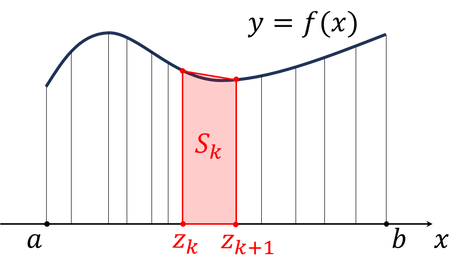

*Геометрическая интерпретация формулы трапеций*

Поскольку оценка погрешности $\Delta_1$ пропорциональна второй степени мелкости основной сетки, **формула трапеций имеет второй порядок аппроксимации**.

## Формула Симпсона

Положим $n=2$. Вычисляем интегралы $\Omega_n^{(i)}$:

$$\Omega_2^{(0)}=\int\limits_{-1}^1\mathop{dy}y(y-1)=\frac{2}{3},\quad \Omega_2^{(1)}=\int\limits_{-1}^1\mathop{dy}\,(y+1)(y-1)=-\frac{4}{3}.$$

Мы не выписали интеграл $\Omega_2^{(2)}$, поскольку его не требуется специально вычислять — достаточно воспользоваться свойством симметрии:

$$\Omega_2^{(2)}=\Omega_2^{(2-0)}=\Omega_2^{(0)}=\frac{2}{3}.$$

Частичная квадратурная сумма:

$$\begin{align}
  \widetilde{I}_k=h_k\cdot\frac{2^2}{2^3}\cdot\bigg[f(\widehat{x}_0)&\cdot\Omega_2^{(0)}\cdot\frac{1}{0-1}\cdot\frac{1}{0-2}+f(\widehat{x}_1)\cdot\Omega_2^{(1)}\cdot\frac{1}{1-0}\cdot\frac{1}{1-2}+\\
  &+f(\widehat{x}_2)\cdot\Omega_2^{(2)}\cdot\frac{1}{2-0}\cdot\frac{1}{2-1}\bigg]=h_k\cdot\bigg[\frac{1}{6}f(\widehat{x}_0)+\frac{2}{3}f(\widehat{x}_1)+\frac{1}{6}f(\widehat{x}_2)\bigg].
  \end{align}$$

Составная квадратурная формула:

$$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}h_k\cdot \bigg[\frac{1}{6}f(\widehat{x}_0)+\frac{2}{3}f(\widehat{x}_1)+\frac{1}{6}f(\widehat{x}_2)\bigg]\equiv\sum\limits_{k=0}^{N-1}\frac{h_k}{6}\cdot \bigg[f(z_k)+4f(z_{k+1/2})+f(z_{k+1})\bigg].$$

Здесь использовано общепринятое в литературе обозначение $z_{k+1/2}$ для узла $\widehat{x}_1$. Имеется в виду, что узлы $\widehat{x}_0$ и $\widehat{x}_2$ "мелкой" сетки совпадают с узлами $z_k$ и $z_{k+1}$ основной сетки, а узел $\widehat{x}_1$ делит частичный отрезок интегрирования $[z_k,z_{k+1}]$ пополам. Подобные обозначения упрощают итоговый вид формул, избавляя от необходимости оставлять двойную нумерацию узлов для двух типов сеток.

Поскольку $n$ чётно, для оценки погрешности, как уже отмечалось, вместо интеграла $\Omega_2$ (который равен нулю) надо вычислить интеграл

$$\Omega_2'=\int\limits_{-1}^1\mathop{dy}y^2(y+1)(y-1)=-\frac{4}{15}.$$

Оценка погрешности:

$$\Delta_2'=\frac{M_4\cdot |\Omega_2'|}{2^5\cdot 4!}\cdot h^4 (b-a)=\frac{M_4h^4}{2880}\cdot (b-a).$$

Выведенная формула называется **формулой Симпсона**. Как видим, **она имеет четвёртый порядок аппроксимации**.



## Правило 3/8

Перейдём к случаю $n=3$. Снова выписываем и вычисляем интегралы $\Omega_n$ и $\Omega_n^{(i)}$:

$$\Omega_3=\int\limits_{-1}^1\mathop{dy}\,(y+1)\bigg(y+\frac{1}{3}\bigg)\bigg(y-\frac{1}{3}\bigg)(y-1)=-\frac{16}{135};$$

$$\Omega_3^{(0)}=\int\limits_{-1}^1\mathop{dy}\,\bigg(y+\frac{1}{3}\bigg)\bigg(y-\frac{1}{3}\bigg)(y-1)=-\frac{4}{9},\quad \Omega_3^{(1)}=\int\limits_{-1}^1\mathop{dy}\,(y+1)\bigg(y-\frac{1}{3}\bigg)(y-1)=\frac{4}{9}.$$

Значения оставшихся интегралов устанавливаем с помощью свойства симметрии:

$$\Omega_3^{(2)}=\Omega_3^{(3-1)}=-\Omega_3^{(1)}=-\frac{4}{9};\qquad \Omega_3^{(3)}=\Omega_3^{(3-0)}=-\Omega_3^{(0)}=\frac{4}{9}.$$

Квадратурная сумма (на $k$-м частичном отрезке):

$$\begin{align}
   \widetilde{I}_k=h_k\cdot\frac{3^3}{2^4}\cdot\bigg[&f(\widehat{x}_0)\cdot\Omega_3^{(0)}\cdot\frac{1}{0-1}\cdot\frac{1}{0-2}\cdot\frac{1}{0-3}+f(\widehat{x}_1)\cdot\Omega_3^{(1)}\cdot\frac{1}{1-0}\cdot\frac{1}{1-2}\cdot\frac{1}{1-3}\,+\\
   +\,&f(\widehat{x}_2)\cdot\Omega_3^{(2)}\cdot\frac{1}{2-0}\cdot\frac{1}{2-1}\cdot\frac{1}{2-3}+f(\widehat{x}_3)\cdot\Omega_3^{(3)}\cdot\frac{1}{3-0}\cdot\frac{1}{3-1}\cdot\frac{1}{3-2}\bigg]=\\
   =h_k\cdot \bigg[&\frac{1}{8}f(\widehat{x}_0)+\frac{3}{8}f(\widehat{x}_1)+\frac{3}{8}f(\widehat{x}_2)+\frac{1}{8}f(\widehat{x}_3)\bigg].
  \end{align}$$

Соответствующая квадратурная формула:

$$\begin{align}
  I\simeq \widetilde{I}&=\sum\limits_{k=0}^{N-1}h_k\cdot \bigg[\frac{1}{8}f(\widehat{x}_0)+\frac{3}{8}f(\widehat{x}_1)+\frac{3}{8}f(\widehat{x}_2)+\frac{1}{8}f(\widehat{x}_3)\bigg]\equiv\\
  &\equiv\sum\limits_{k=0}^{N-1}h_k\cdot \bigg[\frac{1}{8}f(z_k)+\frac{3}{8}f(z_{k+1/3})+\frac{3}{8}f(z_{k+2/3})+\frac{1}{8}f(z_{k+1})\bigg]
  \end{align}$$

(обозначения $z_{k+1/3}$ и $z_{k+2/3}$ вводятся по аналогии с обозначением $z_{k+1/2}$ в случае формулы Симпсона). Её погрешность оценивается величиной:

$$\Delta_3=\frac{M_4\cdot |\Omega_3|}{2^5\cdot 4!}\cdot h^4 (b-a)=\frac{M_4h^4}{6480}\cdot (b-a).$$

Эту квадратурную формулу часто называют **"правилом 3/8"**, имея в виду, что наибольший по модулю весовой коэффициент равен $3/8$. Из оценки погрешности следует, что **"правило 3/8" имеет четвёртый порядок аппроксимации**.

## Формула прямоугольников

Мы получили несколько формул Ньютона—Котеса с ненулевыми $n$. Рассмотрим теперь случай $n=0$. Формально подставить это значение в интегралы $\Omega_n$ и $\Omega_n^{(i)}$ не удаётся: возникает деление на нуль. С другой стороны, если $n=0$, то все "мелкие" сетки содержат по одному узлу $y_0$ (вырождаются), так что подынтегральное выражение в $\Omega_0$ содержит лишь скобку $(y-y_0)$. Далее, при единственном узле в сетке вспомогательные полиномы Лагранжа $\ell_i(x)$ утрачивают смысл: интерполяция на "сетке" из одного узла сводится просто к тому, что значение функции-образа в этом узле определяется по значению функции-оригинала в том же узле; поэтому $\ell_0(x)\equiv 1$. Таким образом,

$$\Omega_0=\int\limits_{-1}^1\mathop{dy}\,(y-y_0)=-2y_0,\quad\Omega_0^{(0)}=\int\limits_{-1}^1\mathop{dy}=2$$

и квадратурная сумма на частичном отрезке интегрирования записывается так:

$$\widetilde{I}_k=h_k\cdot \frac{1}{2^1}\cdot f(\widehat{x}_0)\cdot 2=h_k\cdot f(\widehat{x}_0).$$

Соответствующая квадратурная формула:

$$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}h_k\cdot f(\widehat{x}_0).$$

Оценка погрешности:

$$\Delta_0=\frac{M_{1}\cdot|\Omega_0|}{2^{2}\cdot 1!}\cdot h^{1} (b-a)=\frac{M_{1}h}{2}\cdot (b-a)\cdot|y_0|.$$

Построенная формула называется **формулой прямоугольников**. Из выписанной оценки погрешности следует, что если $y_0\neq 0$, то эта формула имеет первый порядок аппроксимации. Предположим, что $y_0=0$; это значит, что в качестве единственного узла "сетки" выбирается середина отрезка $[-1,1]$ (иначе говоря, $\widehat{x}_0=z_{k+1/2}$). Тогда $\Omega_0=0$, порядок аппроксимации повышается и "работает" правило оценки погрешности при чётном $n$: более точная оценка записывается как

$$\Delta_0'=\frac{M_{2}\cdot|\Omega_0'|}{2^{3}\cdot 2!}\cdot h^{2} (b-a),\quad \Omega_0'=\int\limits_{-1}^1\mathop{dy}\,y^2=\frac{2}{3}.$$

Итак, для получения формулы второго порядка аппроксимации надо брать значения подынтегральной функции в серединах частичных отрезков интегрирования $[z_k,z_{k+1}]$:

$$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}h_k\cdot f(z_{k+1/2}).$$

В этом случае оценка погрешности пропорциональна второй степени мелкости основной сетки (а не первой, как при ином выборе единственного узла):

$$\Delta_0'=\frac{M_2h^2}{24}\cdot (b-a).$$

В дальнейшем мы будем рассматривать оба упомянутых варианта формулы прямоугольников: **формулу с центральной точкой** ($y_0=0$), имеющую, как мы выяснили, **второй порядок аппроксимации**, и "обычную" формулу прямоугольников ($y_0\neq 0$) с **первым порядком аппроксимации**. Для определённости при записи "обычной" формулы будем считать, что $y_0=z_k$, т.е. что единственный узел "мелкой" сетки совпадает с левой границей частичного отрезка интегрирования; ничто не мешает выбрать в качестве $y_0$ и правую границу отрезка $[z_k,z_{k+1}]$: $y_0=z_{k+1}$ (или, вообще говоря, любую точку отрезка $[z_k,z_{k+1}]$, отличную от $z_{k+1/2}$) — это не меняет сути дела.

**Упражнение 2.** Дайте геометрическую интерпретацию формуле прямоугольников. На что влияет (с геометрической точки зрения) выбор единственного узла интерполяции $y_0\neq 0$ в случае "обычной" формулы? Другими словами, чем отличаются, например, случаи $\widehat x_0=z_k$, $\widehat x_0=z_{k+1}$; соответственно $y_0=-1$, $y_0=1$?

## Сводка составных формул Ньютона—Котеса. Формулы высших порядков

Выше мы вывели четыре составные формулы Ньютона—Котеса. Выпишем их ещё раз вместе с соответствующими оценками погрешностей.

* Формула прямоугольников ($n=0$, первый порядок аппроксимации):
  $$I\simeq\widetilde{I}=\sum\limits_{k=0}^{N-1}h_k\cdot f(z_k),\quad  \Delta_0=\frac{M_{1}h}{2}\cdot (b-a);$$

  её вариант — формула прямоугольников с центральной точкой (тоже $n=0$, но второй порядок аппроксимации за счёт выбора единственного узла интерполяции в середине частичного отрезка интегрирования):

  $$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}h_k\cdot f(z_{k+1/2}),\quad \Delta_0'=\frac{M_2h^2}{24}\cdot (b-a).$$

* Формула трапеций ($n=1$, второй порядок аппроксимации):

  $$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}\frac{h_k}{2}\cdot \bigg[f(z_k)+f(z_{k+1})\bigg],\quad \Delta_1=\frac{M_2h^2}{12}\cdot (b-a).$$

* Формула Симпсона ($n=2$, четвёртый порядок аппроксимации):

  $$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}\frac{h_k}{6}\cdot \bigg[f(z_k)+4f(z_{k+1/2})+f(z_{k+1})\bigg],\quad \Delta_2'=\frac{M_4h^4}{2880}\cdot (b-a).$$

* "Правило 3/8" ($n=3$, четвёртый порядок аппроксимации):

  $$I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}\frac{h_k}{8}\cdot \bigg[f(z_k)+3f(z_{k+1/3})+3f(z_{k+2/3})+f(z_{k+1})\bigg],\quad \Delta_3=\frac{M_4h^4}{6480}\cdot (b-a).$$

Отметим, что все полученные оценки верны в предположении непрерывности и ограниченности $(n+1)$-й производной подынтегральной функции на отрезке $[a,b]$ (константа $M_{i}$ должна быть конечной).

Можно было бы и дальше увеличивать $n$, т.е. полагать $n=4$, $n=5$ и т.д., получая всё новые составные формулы Ньютона—Котеса с помощью выписанных выше общих соотношений. Приведём для полноты несколько таких формул:

$${\small
\begin{align}
  n=4:\quad &I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}\frac{h_k}{90}\cdot \bigg[7f(z_k)+32f(z_{k+1/4})+12f(z_{k+1/2})+32f(z_{k+3/4})+7f(z_{k+1})\bigg];\\[6pt]
  n=5:\quad &I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}\frac{h_k}{288}\cdot \bigg[19f(z_k)+75f(z_{k+1/5})+50f(z_{k+2/5})+50f(z_{k+3/5})+75f(z_{k+4/5})+19f(z_{k+1})\bigg];\\[6pt]
  n=6:\quad &I\simeq \widetilde{I}=\sum\limits_{k=0}^{N-1}\frac{h_k}{840}\cdot \bigg[41f(z_k)+216f(z_{k+1/6})+27f(z_{k+1/3})+272f(z_{k+1/2})+27f(z_{k+2/3})+216f(z_{k+5/6})+41f(z_{k+1})\bigg].
\end{align}
}$$

**Упражнение 3.** Вывести выписанные выше квадратурные формулы с $n=4$, $n=5$, $n=6$. Получить для них оценки погрешностей.

Отметим, что формулы Ньютона—Котеса с $n>3$ на практике почти не используются, так как при соответствующих расчётах обнаруживается значительное влияние на результат вычислений погрешностей округления и входных данных (значений подынтегральной функции). Ещё хуже обстоят дела с формулами Ньютона—Котеса при $n\geq 10$. Можно показать, что **если $n\geq 10$, то в формуле Ньютона—Котеса обязательно встретится отрицательный весовой коэффициент** (впервые отрицательный коэффициент появляется уже при $n=8$; при $n=9$ все коэффициенты положительны). С другой стороны, легко доказать, что **сумма весовых коэффициентов любой составной формулы Ньютона—Котеса равна единице**. При таком условии появление отрицательных весовых коэффициентов приводит к увеличению суммы

$$\sum\limits_{i=0}^n|c_i|,$$

а оно влечёт резкий рост погрешности результата из-за наличия ошибок округления и входных данных. Это косвенно связано с экспоненциальным ростом константы Лебега в случае глобальной алгебраической интерполяции на равномерных сетках.

Далее мы будем рассматривать только четыре формулы Ньютона—Котеса, применяющиеся в реальных расчётах: формулы прямоугольников и трапеций, формулу Симпсона, а также "правило 3/8".

## Задача 1

Найти приближённое значение интеграла

$$I=\int\limits_{0}^1\mathop{dx}f(x)$$

по формуле трапеций и по формуле Симпсона. Рассмотреть случаи "простых" и составных формул (при использовании составных формул считать длины частичных отрезков интегрирования равными). Подынтегральная функция задана таблицей.

$$
\begin{array}{c|ccccccccc}
x_i & 0,000 & 0,125 & 0,250 & 0,375 & 0,500\\
\hline
f_i & 1,000000 & 0,984615 & 0,941176 & 0,876712 & 0,800000
\end{array}
$$

$$
\begin{array}{c|ccccccccc}
x_i & 0,625 & 0,750 & 0,875 & 1,000 & \phantom{1,000} \\
\hline
f_i & 0,719101 & 0,640000 & 0,566372 & 0,500000 & \phantom{0,500000}
\end{array}
$$

**Решение.** Функция задана в девяти узлах, разбивающих отрезок интегрирования на **восемь элементарных отрезков**, длина каждого из которых есть $h=1/8$. Для построения формулы трапеций на частичном отрезке интегрирования нужны две точки (являющиеся границами частичного отрезка), т.е. $n=1$. С учётом требования равенства длин всех частичных отрезков, содержащегося в условии задачи, имеем четыре варианта формулы трапеций:

* составная формула, построенная на восьми частичных отрезках длины $h$ (частичные отрезки совпадают с элементарными отрезками), т.е. $K=9$, $N=8$:

  $$I\simeq\widetilde{I}^{(\text{tr})}_h=\sum\limits_{i=0}^7 h\cdot \frac{f(x_i)+f(x_{i+1})}{2}=h\cdot\frac{f(x_0)+f(x_8)}{2}+h\cdot\sum\limits_{i=1}^7 f(x_i);$$

* составная формула, построенная на четырёх частичных отрезках длины $2h$ (элементарные отрезки объединяются в частичные отрезки по два), т.е. $K=5$, $N=4$:
  
  $$I\simeq\widetilde{I}^{(\text{tr})}_{2h}=\sum\limits_{k=0}^3 2h\cdot \frac{f(x_{2k})+f(x_{2k+2})}{2}=h\cdot\big[f(x_0)+f(x_8)\big]+2h\cdot\sum\limits_{k=1}^3 f(x_{2k});$$

* составная формула, построенная на двух частичных отрезках длины $4h$ (элементарные отрезки объединяются в частичные отрезки по четыре), т.е. $K=3$, $N=2$:

  $$I\simeq\widetilde{I}^{(\text{tr})}_{4h}=\sum\limits_{k=0}^1 4h\cdot \frac{f(x_{4k})+f(x_{4k+4})}{2}=2h\cdot\big[f(x_0)+f(x_8)\big]+4h\cdot f(x_{4});$$

* "простая" формула, построенная на всём отрезке интегрирования длины $8h$ (все восемь элементарных отрезков объединяются в один отрезок), т.е. $K=2$, $N=1$:

  $$I\simeq\widetilde{I}^{(\text{tr})}_{8h}=8h\cdot \frac{f(x_{0})+f(x_{8})}{2}=4h\cdot\big[f(x_0)+f(x_8)\big].$$

Остаётся только подставить табличные значения в выписанные формулы (начинаем с конца):

$$\widetilde{I}^{(\text{tr})}_{8h}=0,750000;\quad \widetilde{I}^{(\text{tr})}_{4h}=0,775000;\quad \widetilde{I}^{(\text{tr})}_{2h}=0,782794;\quad \widetilde{I}^{(\text{tr})}_{h}=0,784747.$$

Библиотеки ```numpy``` и ```scipy``` включают несколько различных реализаций методов численного интегрирования, в том числе и квадратурных формул Ньютона—Котеса. Существует, например, функция ```np.trapezoid``` ([документация](https://numpy.org/doc/stable/reference/generated/numpy.trapezoid.html)) для вычисления интеграла по заданной таблице значений подынтегральной функции с помощью формулы трапеций (ср. с выписанными выше значениями):

In [ ]:
import numpy as np

# таблица значений функции
x = np.array([0.000, 0.125, 0.250, 0.375, 0.500, 0.625, 0.750, 0.875, 1.000])
y = np.array([1.000000, 0.984615, 0.941176, 0.876712, 0.800000,
                        0.719101, 0.640000, 0.566372, 0.500000])

In [ ]:
I_8_trap = np.trapezoid(y[0::8], x[0::8])
float(I_8_trap)

0.75

In [ ]:
I_4_trap = np.trapezoid(y[0::4], x[0::4])
float(I_4_trap)

0.775

In [ ]:
I_2_trap = np.trapezoid(y[0::2], x[0::2])
float(I_2_trap)

0.782794

In [ ]:
I_1_trap = np.trapezoid(y, x)
float(I_1_trap)

0.784747

Точно такая же функция есть и в библиотеке ```scipy``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html)) — она входит в модуль ```integrate``` ([документация](https://docs.scipy.org/doc/scipy/reference/integrate.html)).

Аналогично рассматривается формула Симпсона. Она строится по трём узлам на каждом частичном отрезке интегрирования, т.е. $n=2$. По условию длины всех частичных отрезков должны быть равны. Значит, имеем три варианта формулы Симпсона:

* составная формула, построенная на четырёх частичных отрезках длины $2h$ (элементарные отрезки объединяются в частичные отрезки по два), т.е. $K=9$, $N=4$:

  $$\begin{align}
  I\simeq\widetilde{I}^{(\text{Sim})}_{2h}&=\sum\limits_{k=0}^32h\cdot\frac{f(x_{2k})+4f(x_{2k+1})+f(x_{2k+2})}{6}=\\
  &=h\cdot\frac{f(x_{0})+f(x_{8})}{3}+\frac{2h}{3}\cdot \sum\limits_{k=1}^3f(x_{2k})+\frac{4h}{3}\cdot \sum\limits_{k=0}^3f(x_{2k+1});
  \end{align}$$

* составная формула, построенная на двух частичных отрезках длины $4h$ (элементарные отрезки объединяются в частичные отрезки по четыре), т.е. $K=5$, $N=2$:

  $$\begin{align}
  I\simeq\widetilde{I}^{(\text{Sim})}_{4h}&=\sum\limits_{k=0}^14h\cdot\frac{f(x_{4k})+4f(x_{4k+2})+f(x_{4k+4})}{6}=\\[0.2cm]
  &=\frac{2h}{3}\cdot\big[f(x_0)+f(x_8)\big]+\frac{8h}{3}\cdot\big[f(x_2)+f(x_6)\big]+\frac{4h}{3}\cdot f(x_4);
  \end{align}$$

* "простая" формула, построенная на всём отрезке интегрирования длины $8h$ (все восемь элементарных отрезков объединяются в один отрезок), т.е. $K=3$, $N=1$:

  $$I\simeq\widetilde{I}^{(\text{Sim})}_{8h}=8h\cdot \frac{f(x_{0})+4f(x_{4})+f(x_{8})}{6}=\frac{4h}{3}\cdot\big[f(x_0)+4f(x_4)+f(x_8)\big].$$

После подстановки табличных значений функции имеем:

$$\widetilde{I}^{(\text{Sim})}_{8h}=0,783333;\quad \widetilde{I}^{(\text{Sim})}_{4h}=0,785392;\quad \widetilde{I}^{(\text{Sim})}_{2h}=0,785398.$$

Вычисления с помощью функции ```simpson``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.simpson.html)) из модуля ```integrate``` библиотеки ```scipy``` ([документация](https://docs.scipy.org/doc/scipy/reference/integrate.html)):

In [ ]:
from scipy.integrate import simpson

I_8_Sim = simpson(y[0::4], x[0::4])
float(I_8_Sim)

0.7833333333333333

In [ ]:
I_4_Sim = simpson(y[0::2], x[0::2])
float(I_4_Sim)

0.785392

In [ ]:
I_2_Sim = simpson(y, x)
float(I_2_Sim)

0.7853979999999998

В условии задачи дана таблица значений функции $f(x)=1/(1+x^2)$, поэтому точное значение интеграла есть

$$I=\int\limits_{0}^1\frac{dx}{1+x^2}=\text{arctg}(1)-\text{arctg}(0)=\frac{\pi}{4}= 0,785398\dots\,.$$

Знание точного значения интеграла $I$ позволяет нам найти погрешности применённых квадратурных формул. Например, в случае формулы трапеций:

In [ ]:
eps_trap = np.abs(np.array([I_8_trap, I_4_trap, I_2_trap, I_1_trap]) - np.pi / 4)
eps_trap

array([0.03539816, 0.01039816, 0.00260416, 0.00065116])

Составляя отношения вычисленных погрешностей и логарифмируя их по основанию 2 (поскольку шаг при переходе от одной "основной" сетки к другой измельчается в два раза: $8h$, $4h$, $2h$, $h$), получаем **порядок сходимости** формулы трапеций:

In [ ]:
np.log2(eps_trap[:-1] / eps_trap[1:])

array([1.76734578, 1.99743685, 1.99972846])

Видно, что при измельчении сеток значение порядка **сходимости** приближается к двум. Ранее мы установили, что формула трапеций имеет второй порядок **аппроксимации**, если вторая производная подынтегральной функции непрерывна и ограничена на отрезке интегрирования. Легко видеть, что при $f(x)=1/(1+x^2)$ и $x\in[0,1]$ это условие удовлетворяется, поэтому реальный порядок сходимости и совпадает (в пределе) с порядком аппроксимации.

Аналогично можно найти погрешности приближённых значений интеграла $I$, полученных с помощью различных вариантов формулы Симпсона:

In [ ]:
eps_Sim = np.abs(np.array([I_8_Sim, I_4_Sim, I_2_Sim]) - np.pi / 4)
eps_Sim

array([2.06483006e-03, 6.16339745e-06, 1.63397448e-07])

Логарифмируя по основанию 2 отношения этих погрешностей, получаем:

In [ ]:
np.log2(eps_Sim[:-1] / eps_Sim[1:])

array([8.38808151, 5.23726847])

Как видим, найденные значения превосходят ожидаемую величину. В самом деле, формула Симпсона имеет четвёртый порядок аппроксимации, и поэтому естественно считать, что порядок сходимости также должен равняться четырём (во всяком случае, не должен быть больше четырёх). Наблюдаемое несоответствие не объясняется только выбором недостаточно подробных сеток. Обратим внимание на то, что полученные величины ошибок сопоставимы по величине с ошибками входных данных. Получим более полную картину изменения порядка сходимости. Для этого, отвлекаясь от условия задачи, возьмём несколько более подробных сеток и зададим значения подынтегральной функции с точностью до ошибок округления:

In [ ]:
def Simpson_grid_test(n: int):
    x = np.linspace(0.0, 1.0, n+1) # шаг h = 1 / n
    y = 1 / (1 + x**2)

    eps_Sim = []
    for i in range(5, -1, -1):
        eps_Sim.append(simpson(y[0::2**i], x[0::2**i]))

    eps_Sim = np.abs(np.array(eps_Sim) - np.pi/4)

    return np.log2(eps_Sim[:-1] / eps_Sim[1:])

In [ ]:
from ipywidgets import interact, IntSlider

n_w = IntSlider(min=64, max=192, step=64, value=64)

interact(Simpson_grid_test, n=n_w);

interactive(children=(IntSlider(value=64, description='n', max=192, min=64, step=64), Output()), _dom_classes=…

Таким образом, реальный порядок сходимости равен шести (а не четырём, как можно было бы предполагать). Причину его повышения можно объяснить с помощью формулы Эйлера—Маклорена (см. ниже).

# Метод Рунге—Ричардсона

Итак, нами получены четыре квадратурные формулы Ньютона—Котеса и оценки для их погрешностей. Приступая к практическому применению этих формул, мы сталкиваемся с вопросом о выборе оптимальных длин частичных отрезков интегрирования. Иначе говоря, **перед проведением вычислений необходимо понять, насколько мелкую основную сетку следует выбрать, чтобы получить приближённое значение искомого интеграла $I$ с точностью не хуже $\varepsilon$**. Разумеется, этот вопрос имеет смысл лишь в тех случаях, когда значения подынтегральной функции доступны в произвольно выбранных узлах.

На первый взгляд кажется, что ответ на поставленный вопрос в каждом конкретном случае следует из выведенных оценок на погрешности $|I-\widetilde{I}|$. Так, если мы хотим, чтобы расчёт по формуле трапеций дал значение интеграла с точностью $\varepsilon$, то, очевидно, надо брать сетку с мелкостью

$$h\leq h_{\varepsilon}=\sqrt{\frac{12\varepsilon}{M_2(b-a)}},$$

т.е. — в простейшем случае — равномерную сетку с шагом $h_{\varepsilon}$ (если $h_{\varepsilon}$ укладывается в отрезок интегрирования целое число раз). Однако константа $M_2$, как правило, бывает неизвестна (если интегрируется, скажем, таблично заданная функция) или трудноопределима (подынтегральная функция зачастую представляет собой довольно сложную комбинацию элементарных функций). Поэтому возникает необходимость получать не только теоретические (или, как принято говорить, **априорные**), но и практические (или **апостериорные**) оценки погрешностей формул Ньютона—Котеса. Апостериорные оценки устанавливаются **непосредственно в процессе приближённого вычисления интеграла**, без необходимости предварительного определения каких-то констант (например, констант $M_i$).

Для апостериорной оценки погрешностей формул Ньютона—Котеса обычно используют **приём сгущения сеток** (его также называют **методом Рунге—Ричардсона**). Мы изложим суть этого приёма в простейшем случае **равномерных сеток**, хотя его можно обобщить и на случай неравномерных сеток.

Пусть интеграл $I$ вычислен приближённо по некоторой формуле Ньютона—Котеса, имеющей $p$-й порядок аппроксимации. Ориентируясь на полученные ранее оценки погрешностей, можем написать:

$$I\simeq\widetilde{I}+C_0\cdot h^p.$$

Здесь $\widetilde{I}$ — соответствующая квадратурная сумма, $h$ — шаг равномерной сетки (т.е. длина каждого из частичных отрезков интегрирования $[z_k,z_{k+1}]$), $C_0$ — константа, **не зависящая от шага сетки**. Например, в случае той же формулы трапеций $p=2$, а $|C_0|\leq M_2(b-a)/12$.

Будем сгущать введённую на отрезке $[a,b]$ сетку, уменьшая её шаг $h$ (и, соответственно, увеличивая число узлов $z_k$). В пределе $h\to 0$ выписанное выше приближённое равенство можно заменить точным равенством:

$$I=\widetilde{I}+C_0\cdot h^p+o(h^p)\equiv \widetilde{I}+\Delta_h,\quad h\to 0.$$

С практической точки зрения эта формула означает, что, когда шаг сетки очень мал, погрешность вычисления интеграла $\Delta_h$ очень близка к своему главному члену $C_0\cdot h^p$. Подчеркнём, что сама величина $\Delta_h$ имеет $(p-1)$-й порядок малости по $h$: $\Delta_h=o(h^{p-1})$. Мы ещё обратим внимание на это обстоятельство.

Пусть расчёт по выбранной формуле Ньютона—Котеса выполнен на двух сетках с шагами $h$ и $h/q$, причём $q>1$, т.е. вторая сетка является более подробной. В первом случае интеграл приближается квадратурной суммой $\widetilde{I}_h$, во втором — суммой $\widetilde{I}_{h/q}$. Согласно сказанному выше, имеем равенства:

$$I=\widetilde{I}_h+C_0\cdot h^p+o(h^p)\equiv \widetilde{I}_h+\Delta_h,\quad I=\widetilde{I}_{h/q}+C_0\cdot q^{-p}\cdot h^p+o(h^p)\equiv \widetilde{I}_{h/q}+\Delta_{h/q}.$$

Здесь существенно, что константа $C_0$ в обоих случаях одинакова (поскольку она не зависит от шага $h$). Вычитая одно равенство из другого, находим, что

$$C_0=\frac{\widetilde{I}_{h/q}-\widetilde{I}_h}{1-q^{-p}}\cdot h^{-p}+o(1).$$

Поэтому для погрешности $\Delta_{h/q}$ справедлива **первая формула Ричардсона**:

$$\Delta_{h/q}=\frac{\widetilde{I}_{h/q}-\widetilde{I}_h}{q^p-1}+o(h^p)\equiv \Delta^{(\text{Rich})}+o(h^p),\quad h\to 0.$$

Фигурирующую здесь величину $\Delta^{(\text{Rich})}\equiv(\widetilde{I}_{h/q}-\widetilde{I}_h)/(q^p-1)$ иногда называют **поправкой Ричардсона** (смысл этого названия выяснится из дальнейшего).

Отбрасывая в первой формуле Ричардсона член $o(h^p)$, получаем апостериорную оценку погрешности численного интегрирования по выбранной формуле Ньютона—Котеса через модуль поправки Ричардсона (**оценка относится к более подробной сетке!**):

$$\big|I-\widetilde{I}_{h/q}\big|\simeq \frac{\big|\widetilde{I}_{h/q}-\widetilde{I}_h\big|}{q^p-1}\equiv \big|\Delta^{(\text{Rich})}\big|.$$

Следует помнить, что эта оценка является **асимптотически точной** (т.е. она точна в пределе $h\to 0$), и поэтому её можно применять лишь при достаточно малых $h$; на чересчур грубых сетках она может оказаться неверной. Заметим также, что для вычисления поправки Ричардсона достаточно знать только порядок аппроксимации $p$ используемой формулы Ньютона—Котеса; какие-либо специальные сведения о подынтегральной функции (наподобие констант $M_i$) не требуются. Выбор величины $q>1$ (**коэффициента измельчения сетки**) находится в руках исследователя. На практике очень часто полагают $q=2$ (т.е. при переходе к новой сетке каждый частичный отрезок интегрирования $[z_k,z_{k+1}]$ делят пополам), хотя это значение $q$ не всегда является оптимальным (см. ниже).

Вернёмся к задаче вычисления интеграла $I$ с фиксированной точностью $\varepsilon$. Апостериорная оценка погрешности через модуль поправки Ричардсона наводит на мысль многократно измельчать сетку в $q>1$ раз до тех пор, пока очередная оценка, найденная по двум "соседним" значениям квадратурной суммы $\widetilde{I}_h$ и $\widetilde{I}_{h/q}$, не окажется меньше $\varepsilon$. Алгоритм может выглядеть так:

1. вычисляем квадратурную сумму $\widetilde{I}_h$ на равномерной сетке с шагом $h$; эту величину называем **текущей квадратурной суммой**: $\widetilde{I}_\text{curr}\equiv\widetilde{I}_h$; шаг $h$ называем **текущим шагом**;

2. измельчаем сетку, уменьшая текущий шаг в $q>1$ раз, и вычисляем ещё одну квадратурную сумму $\widetilde{I}_{h/q}$; её называем **следующей квадратурной суммой**: $\widetilde{I}_\text{next}\equiv\widetilde{I}_{h/q}$, а шаг $h/q$ — **следующим шагом**;

3. находим модуль поправки Ричардсона:
   
   $$\big|\Delta^{(\text{Rich})}\big|=\frac{\big|\widetilde{I}_\text{next}-\widetilde{I}_\text{curr}\big|}{q^p-1};$$

4. если $\big|\Delta^{(\text{Rich})}\big|\leq\varepsilon$, то останавливаем алгоритм и берём в качестве искомого значения интеграла величину $\widetilde{I}_\text{next}$;

5. если условие $\big|\Delta^{(\text{Rich})}\big|\leq\varepsilon$ не выполнено, то возвращаемся к первому пункту, принимая за текущие значения суммы и шага величины $\widetilde{I}_\text{next}$ и $h/q$ соответственно.





Приведём пример использования предложенного алгоритма. В качестве тестовой задачи возьмём интеграл

$$I_1=\int\limits_1^4\frac{dx}{\sqrt{x}},$$

который легко найти аналитически: $I_1=2$. Будем вычислять этот интеграл приближённо по формуле трапеций. Расчёт квадратурной суммы $\widetilde{I}_h$ при заданном $h$ организуем в виде функции ```calc_int1```, использующей встроенную реализацию формулы трапеций ```np.trapezoid``` (мы уже использовали её выше):

In [ ]:
import numpy as np

def calc_int1(h: float):
    f = np.vectorize(lambda x: 1 / np.sqrt(x))
    x = np.arange(1, 4 + h/2, h) # сетка, включающая последний узел

    return np.trapezoid(f(x), x)

Описанный выше алгоритм, использующий идею последовательного сгущения сеток, реализуем в виде функции ```Runge_method```:

In [ ]:
def Runge_method(integrator, p: float, eps: float, h_init: float,
                 q: float = 2, max_iter: int = 55):
    h_curr = h_init
    I_curr = integrator(h_curr) # расчёт квадратурной суммы "вычислительным ядром"

    I_list = []
    delta_Rich_list = []

    for i in range(max_iter):
        # сохранение текущего значения квадратурной суммы
        I_list.append(float(I_curr))

        h_next = h_curr / q
        I_next = integrator(h_next)

        delta_Rich = abs(I_next - I_curr) / (q**p - 1)

        # сохранение значения поправки Ричардсона
        delta_Rich_list.append(float(delta_Rich))

        if delta_Rich <= eps:
            I_list.append(float(I_next))
            break

        # подготовка к следующей итерации
        h_curr = h_next
        I_curr = I_next

    return I_list, delta_Rich_list

По умолчанию мы положили $q=2$ — как уже отмечалось, это значение коэффициента измельчения сетки используется на практике чаще всего. Очевидно, что если значение шага сетки достигает предела двойной точности $10^{-16}$, то продолжать измельчение не имеет смысла; значит, в качестве максимально допустимого числа итераций следует выбрать величину $\sim\ln 10^{16}/\ln 2\simeq 54$, что мы и сделали. Заметим, что в программу намеренно добавлено сохранение всех промежуточных приближений к значению интеграла и всех поправок Ричардсона (это необходимо для дальнейшего обсуждения примера). На практике достаточно запоминать и возвращать лишь последнее приближённое значение интеграла $I_\text{next}$, а также все поправки Ричардсона (т.е. сохранять промежуточные значения квадратурных сумм не обязательно). Для чего при реальных расчётах необходим массив поправок Ричардсона, мы увидим далее.

Запустим расчёт интеграла от начального шага $h=0,1$ и потребуем достижения точности $\varepsilon=10^{-8}$. Поскольку мы используем формулу трапеций, $p=2$.

In [ ]:
I_list, delta_Rich_list = Runge_method(calc_int1, p=2, eps=1e-8, h_init=0.1)
I_list, delta_Rich_list = np.array(I_list), np.array(delta_Rich_list)

Нам известно точное значение интеграла, поэтому для всех найденных квадратурных сумм можно рассчитать погрешности. По каждой паре значений из массива погрешностей легко определить порядок сходимости:

In [ ]:
err = np.abs(I_list - 2)
p_real = np.log2(err[:-1] / err[1:]) # логарифм по основанию 2, так как q=2

Сведём все результаты в таблицу (для построения таблицы пользуемся средствами библиотеки ```pandas``` — [документация](https://pandas.pydata.org/docs/)):

In [ ]:
# сдвиг поправок Ричардсона и порядков сходимости на одну строку таблицы вниз
# (для определения обеих величин нужно ДВА значения квадратурной суммы,
# поэтому их удаётся вычислить, начиная со второй по порядку суммы)

p_for_table = np.concatenate([[np.nan], p_real])
delta_for_table = np.concatenate([[np.nan], delta_Rich_list])

In [ ]:
import pandas as pd

# создание таблицы
table_dict = {'Квадратурная сумма': I_list,
              'Погрешность': err,
              'Поправка Ричардсона': delta_for_table,
              'Порядок сходимости': p_for_table}

table_df = pd.DataFrame(table_dict)

# форматирование чисел и замена пропусков
table_df = table_df.style.format({'Квадратурная сумма': '{:.8f}',
                                  'Погрешность': '{:.4e}',
                                  'Поправка Ричардсона': '{:.4e}',
                                  'Порядок сходимости': '{:.4f}'}, na_rep='—')

# установка ширины столбцов
table_df = table_df.set_properties(**{'width': '120px'})

In [ ]:
table_df

,Квадратурная сумма,Погрешность,Поправка Ричардсона,Порядок сходимости
0,2.00036433,3.6433e-04,—,—
1,2.00009113,9.1130e-05,9.1065e-05,1.9992
2,2.00002279,2.2785e-05,2.2781e-05,1.9998
3,2.00000570,5.6966e-06,5.6963e-06,2.0000
4,2.00000142,1.4241e-06,1.4241e-06,2.0000
5,2.00000036,3.5604e-07,3.5604e-07,2.0000
6,2.00000009,8.9010e-08,8.9010e-08,2.0000
7,2.00000002,2.2252e-08,2.2252e-08,2.0000
8,2.00000001,5.5634e-09,5.5630e-09,1.9999


Как видим, для достижения заданной точности $\varepsilon=10^{-8}$ понадобилось измельчить сетку восемь раз. Заметим, что после третьего измельчения значения погрешностей результата и модулей поправок Ричардсона начинают совпадать друг с другом в первых восьми знаках. Для более детального анализа можно в каждом случае найти разности этих величин:

In [ ]:
err[1:] - delta_Rich_list

array([ 6.42933330e-08,  4.03245866e-09,  2.52246224e-10,  1.57998059e-11,
        1.00704630e-12, -5.95079541e-14, -8.11202957e-14,  4.83465120e-13])

Видно, что при малых шагах сетки отличия поправок Ричардсона от погрешностей выходят на значения порядка $10^{-14}$, т.е. практически на уровень ошибок округления. Это признак правильной работы алгоритма. Убедиться в его корректности можно и по последнему столбцу таблицы: видно, что с уменьшением шага сетки реальный порядок сходимости стремится к порядку аппроксимации $p=2$.

Применяя изложенный выше метод Рунге—Ричардсона (приём сгущения сеток) на практике, следует обязательно **контролировать его корректность**, убеждаясь в том, что порядок сходимости (полученный в программе для данного теста) равен порядку аппроксимации (известному из теории и полученному в предположении достаточной гладкости функции). В противном случае нельзя гарантировать асимптотическое совпадение погрешностей квадратурных сумм и модулей поправок Ричардсона, а отсутствие такого совпадения может привести к неверной работе алгоритма.

Попробуем, например, найти интеграл

$$I_2=\int\limits_0^1\mathop{dx}\sqrt{x}=\frac{2}{3}$$

с помощью той же итерационной процедуры. Предварительно для удобства соберём все рассмотренные выше части программы в одну функцию:

In [ ]:
def tester(integrator, p: float, exact_value: float, eps: float, h_init):
    I_list, delta_Rich_list = Runge_method(integrator, p=p, eps=eps, h_init=h_init)

    # расчёт погрешностей и порядков сходимости
    err = np.abs(np.array(I_list) - exact_value)
    p_real = np.log2(err[:-1] / err[1:])

    p_for_table = np.concatenate([[np.nan], p_real])
    delta_for_table = np.concatenate([[np.nan], delta_Rich_list])

    # создание таблицы
    table_dict = {'Квадратурная сумма': I_list,
                  'Погрешность': err,
                  'Поправка Ричардсона': delta_for_table,
                  'Порядок сходимости': p_for_table}

    table_df = pd.DataFrame(table_dict)

    # форматирование чисел и замена пропусков
    table_df = table_df.style.format({'Квадратурная сумма': '{:.8f}',
                                      'Погрешность': '{:.4e}',
                                      'Поправка Ричардсона': '{:.4e}',
                                      'Порядок сходимости': '{:.4f}'}, na_rep='—')

    # установка ширины столбцов
    table_df = table_df.set_properties(**{'width': '120px'})

    return table_df

Как и прежде, будем вычислять интеграл $I_2$ по формуле трапеций ($p=2$). "Вычислительное ядро":

In [ ]:
def calc_int2(h: float):
    f = np.vectorize(lambda x: np.sqrt(x))
    x = np.arange(0, 1 + h/2, h) # сетка, включающая последний узел

    return np.trapezoid(f(x), x)

Запускаем расчёт от того же шага $h=0,1$ с той же требуемой точностью $\varepsilon=10^{-8}$:

In [ ]:
tester(integrator=calc_int2, p=2, exact_value=2/3, eps=1e-8, h_init=0.1)

,Квадратурная сумма,Погрешность,Поправка Ричардсона,Порядок сходимости
0,0.66050934,6.1573e-03,—,—
1,0.66444659,2.2201e-03,1.3124e-03,1.4717
2,0.66587097,7.9570e-04,4.7479e-04,1.4803
3,0.66638265,2.8402e-04,1.7056e-04,1.4862
4,0.66656558,1.0109e-04,6.0976e-05,1.4903
5,0.66663076,3.5909e-05,2.1727e-05,1.4932
6,0.66665393,1.2738e-05,7.7238e-06,1.4952
7,0.66666215,4.5141e-06,2.7413e-06,1.4966
8,0.66666507,1.5986e-06,9.7183e-07,1.4976
9,0.66666610,5.6585e-07,3.4425e-07,1.4983


Хотя $p=2$, порядок сходимости в данном случае не стремится к двойке, что приводит к заметным отличиям модулей поправок Ричардсона от погрешностей квадратурных сумм. Впрочем, в приведённом примере это не помешало получить искомое значение интеграла с требуемой точностью. **В более сложных случаях отличие реального порядка сходимости от теоретического значения (порядка аппроксимации) может привести к неверному результату вычислений!** Что касается причин такого отличия, то их может быть две.

Прежде всего, подчеркнём, что **для корректности апостериорной оценки погрешности формулы Ньютона—Котеса через поправку Ричардсона необходимо существование у подынтегральной функции $f(x)$ производных вплоть до $p$-го порядка включительно ($p$ — порядок аппроксимации формулы), а также непрерывность и ограниченность этих производных на отрезке интегрирования**. Это требование остаётся в силе несмотря на то, что апостериорные оценки, в отличие от априорных, не содержат никаких величин, связанных с производными функции $f(x)$ (например, констант $M_i$). Дело в том, что при выводе первой формулы Ричардсона мы неявно предположили, что функцию $f(x)$ можно в каждой точке отрезка интегрирования представить формулой Тейлора с остаточным членом в форме Пеано, выписав члены вплоть до $p$-го порядка по $h$ включительно. Но этого нельзя сделать, если какая-то из $p$ первых производных функции $f(x)$ терпит разрыв или оказывается неограниченной на отрезке интегрирования, поэтому в подобных случаях первая формула Ричардсона теряет смысл.

В примере с интегралом $I_2$ уже первая производная подынтегральной функции $f(x)=\sqrt{x}$, равная $f'(x)=1/(2\sqrt{x})$, стремится к бесконечности при приближении к левой границе отрезка интегрирования. Это значит, что все теоретические формулы, обосновывающие второй порядок сходимости метода Рунге—Ричардсона при использовании формулы трапеций, "перестают работать", что мы и наблюдаем: реальный порядок сходимости оказался равным $3/2$. Для справки отметим, что в более общем случае вычисления интеграла

$$\int\limits_0^1\mathop{dx}x^{1/n}$$

по формуле трапеций порядок сходимости падает до значения $1+1/n<2$.

С другой стороны, **потеря точности в методе Рунге—Ричардсона может быть вызвана выбором недостаточно подробной сетки**. Повторим, что оценка погрешности через модуль поправки Ричардсона является **асимптотически точной**, и пока шаг сетки недостаточно мал, эта оценка оказывается грубой. Последнее обстоятельство может привести к неверному результату расчёта, если требуемая точность вычисления интеграла $\varepsilon$ не слишком высока.

В следующем примере методом Рунге—Ричардсона вычисляется интеграл

$$I_3=\int\limits_0^1\mathop{dx}x^{1/200}=\frac{200}{201}.$$

"Вычислительное ядро" использует, как и выше, формулу трапеций, а требуемая точность выбрана не очень высокой: $\varepsilon=5\cdot 10^{-3}$:

In [ ]:
def calc_int3(h: float):
    f = np.vectorize(lambda x: x**(1/200))
    x = np.arange(0, 1 + h/2, h) # сетка, включающая последний узел

    return np.trapezoid(f(x), x)

In [ ]:
tester(integrator=calc_int3, p=2, exact_value=200/201, eps=5*1e-3, h_init=0.1)

,Квадратурная сумма,Погрешность,Поправка Ричардсона,Порядок сходимости
0,0.94605313,4.8972e-02,—,—
1,0.97062268,2.4402e-02,8.1899e-03,1.0049
2,0.98286573,1.2159e-02,4.0810e-03,1.0050


В результате совместного влияния двух упомянутых выше факторов: неограниченности производных подынтегральной функции и недостаточной подробности начальной сетки — итерационный процесс останавливается после двух измельчений. При этом происходит потеря точности — заданная погрешность $\varepsilon=5\cdot 10^{-3}$, очевидно, не достигнута.

Итак, **при практических расчётах во избежание потери точности в итоговом ответе нужно обязательно проверять корректность метода Рунге—Ричардсона, контролируя величину порядка сходимости $p^{(\text{real})}$**. В простейших случаях контроль можно осуществлять, например, с помощью таблиц, подобных построенным выше. Нужно только иметь в виду, что в реальных задачах точные значения вычисляемых интегралов неизвестны, и поэтому порядок сходимости $p^{(\text{real})}$ надо определять по значениям из массива поправок Ричардсона (а не из массива ошибок, как во всех примерах выше). Так, в примере с интегралом $I_1$ при отсутствии информации о точном значении этого интеграла действительный порядок сходимости вычислялся бы следующим образом:

In [ ]:
p_real_delta = np.log2(delta_Rich_list[:-1] / delta_Rich_list[1:])

Мы предоставляем читателю самостоятельно внести соответствующее изменение в функцию ```tester```.

При сравнительно большом количестве измельчений сетки удобно визуализировать данные полученных таблиц и контролировать корректность метода Рунге—Ричардсона по графикам. Предварительно рекомендуется перейти от шага сетки $h$ к количеству частичных отрезков интегрирования $N=(b-a)/h$, т.е. перейти к рассмотрению той характеристики сетки, которая увеличивается с её измельчением (подчеркнём, что $N$ не есть количество узлов сетки: количество узлов равно $N+1$). После этого следует построить графики зависимостей величин $\ln\Delta^{(\text{Rich})}$ и $p^{(\text{real})}$ от величины $\ln N$.

Если расчёт по алгоритму Рунге—Ричардсона оказывается корректным, то первый из графиков представляет собой прямую с отрицательным (в силу убывания погрешности квадратурной формулы) угловым коэффициентом, равным по модулю порядку сходимости. По графику удобно проверять монотонность убывания поправок Ричардсона. При малых $N$ (грубые сетки) поведение поправок может быть немонотонным (в этом случае график имеет вид ломаной) — это значит, что алгоритм ещё не вышел на столь малые шаги сеток, чтобы погрешности квадратурных сумм были близки к поправкам Ричардсона (другими словами, из формулы для $\Delta_{h/q}$ ещё нельзя отбрасывать "хвост" $o(h^p)$ и считать, что $\Delta_{h/q}\simeq \Delta^{(\text{Rich})}$ — шаг сетки недостаточно мал). С другой стороны, при очень больших $N$ прямая тоже может превращаться в ломаную. Последнее указывает на чрезмерное измельчение сетки: при слишком малых $h$ на результаты вычислений начинают влиять ошибки округления, и дальнейшее уменьшение шага бессмысленно.

Второй график (зависимость $p^{(\text{real})}$ от $\ln N$) позволяет проверить величину порядка сходимости. В средней своей части он должен представлять собой прямую $y=p^{(\text{real})}$, параллельную оси абсцисс. В областях малых и больших $N$ возможны отклонения от этой прямой, обусловленные описанными выше причинами.

Например, при вычислении интеграла $I_1$ контрольные графики выглядят так:

In [ ]:
# задаём массив из чисел N для сеток, использованных при вычислении интеграла I_1
a = 1
b = 4
h_list = np.array([0.1 / 2**i for i in range(1, 9)])
N_list = (b - a) / h_list

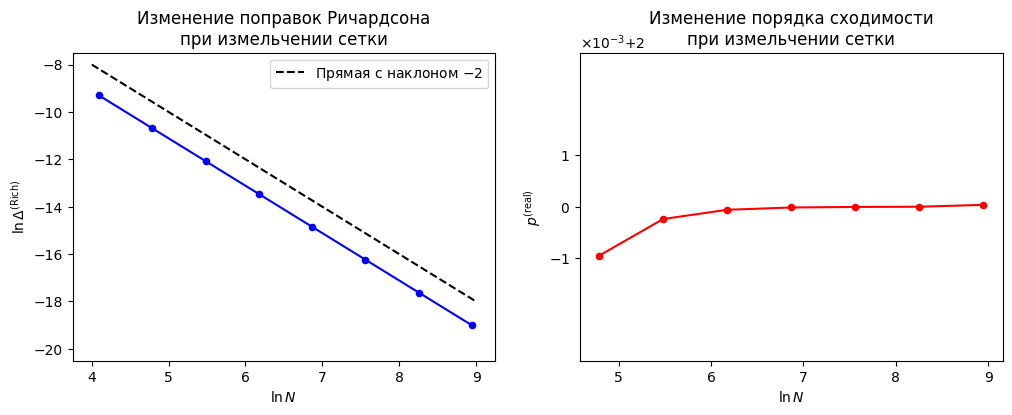

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import ticker

def plot_graphs(delta_Rich_list: np.ndarray, p_delta: np.ndarray, h_list: np.ndarray):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # логарифм поправок Ричардсона от логарифма числа отрезков
    ax1.scatter(np.log(N_list), np.log(delta_Rich_list), color='blue', s=20, zorder=2.1)
    ax1.plot(np.log(N_list), np.log(delta_Rich_list), color='blue', zorder=2)
    ax1.plot([4, 9], [-8, -18], linestyle='dashed', color='k', label='Прямая с наклоном $-2$')

    ax1.set_xlabel('$\\ln N$')
    ax1.set_ylabel('$\\ln\\Delta^{(\\text{Rich})}$')

    ax1.set_yticks([-8, -10, -12, -14, -16, -18, -20])
    ax1.set_ylim([-20.5, -7.5])

    ax1.set_title(r'Изменение поправок Ричардсона'
                  '\n'
                  'при измельчении сетки')

    ax1.legend()

    # порядок сходимости от логарифма числа отрезков
    ax2.scatter(np.log(N_list)[1:], p_delta, color='red', s=20, zorder=2.1)
    ax2.plot(np.log(N_list)[1:], p_delta, color='red', zorder=2)

    ax2.set_xlabel('$\\ln N$')
    ax2.set_ylabel('$p^{(\\text{real})}$')

    ax2.set_yticks([1.999, 2, 2.001])
    ax2.set_ylim([1.997, 2.003])

    # специальный ("научный") формат меток по оси y
    y_ticker = ticker.ScalarFormatter(useMathText=True)
    ax2.yaxis.set_major_formatter(y_ticker)
    ax2.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

    ax2.set_title(r'Изменение порядка сходимости'
                  '\n'
                  'при измельчении сетки')

    plt.show()

plot_graphs(delta_Rich_list, p_real_delta, N_list)

Для наглядности на первом из них мы провели пунктирную прямую с угловым коэффициентом $k=-2$. Вид графиков указывает на корректность метода Рунге—Ричардсона: на рассматриваемых сетках поправки Ричардсона убывают монотонно, причём при измельчении сетки достигается второй порядок сходимости, как и должно быть (напомним, что для вычисления интеграла $I_1$ использовалась формула трапеций).

**Упражнение 4.** Построить аналогичные графики для приведённых выше примеров с интегралами $I_2$ и $I_3$.

Если контроль корректности метода Рунге—Ричардсона показывает, что порядок сходимости меньше порядка аппроксимации, т.е. $p^{(\text{real})}<p$ (как в примере с интегралами $I_2$ и $I_3$), то алгоритм следует несколько модифицировать, добавив в него процедуру апостериорной оценки $p^{(\text{real})}$. Такая модификация приводит к **процессу Эйткена**. Мы рассмотрим его ниже.

Отметим, что везде выше метод Рунге—Ричардсона обсуждался в контексте расчёта приближённых значений определённых интегралов по составным квадратурным формулам Ньютона—Котеса. Однако, его можно применять и к другим квадратурным формулам, например, к составным формулам Гаусса с фиксированным числом узлов на каждом подотрезке при последовательном измельчении сетки. Однако гауссовы узлы на сетках разных уровней, как правило, не являются вложенными, поэтому ранее вычисленные значения подынтегральной функции нельзя использовать повторно. Вследствие этого возрастают вычислительные затраты. Приём последовательного сгущения сеток также  широко используется при анализе разностных схем, предназначенных для решения дифференциальных уравнений и их систем. Мы будем обсуждать соответствующие алгоритмы в следующем семестре.

Когда метод Рунге—Ричардсона обобщается для использования в многомерных задачах (расчёт двойных интегралов, решение уравнений эллиптического типа на плоскости и т.п.), возникает вопрос о выборе оптимального коэффициента измельчения сетки $q$. Значение $q=2$, рекомендуемое во многих источниках, удобно с точки зрения технической реализации алгоритма: в этом случае узлы каждой следующей сетки включают в себя узлы всех предыдущих сеток, так что в совпадающих узлах удобно сравнивать при необходимости значения рассматриваемых функций (например, значения приближённых решений дифференциальных уравнений). С другой стороны, **при $q=2$ каждое сгущение сетки значительно увеличивает объём расчётов**: в одномерных задачах количество узлов возрастает вдвое, в двумерных — вчетверо, в трёхмерных — в восемь раз и т.д. Таким образом, при большом количестве измельчений сетки существенно увеличиваются время расчёта и необходимое количество памяти. Кроме того, при $q=2$ точки на контрольных графиках располагаются сравнительно редко.

Для устранения этих недостатков можно пользоваться специальными наборами сеток, подобранными так, что отношение количеств частичных отрезков интегрирования у "соседних" сеток оказывается не строго постоянным (как в случае $q=2$), а **близким к постоянному** (и меньшим двойки). Например, можно брать сетки со следующими $N$:

$$N_0=5,\quad N_1=7,\quad N_2=10,\quad N_3=14,\quad N_4=20,\quad N_5=28,\quad \dots\,.$$

Коэффициент измельчения $q$ в этой последовательности сеток примерно равен $\sqrt{2}$ (с точностью до $1\%$). На это среднее значение можно ориентироваться при вычислении дальнейших $N$. Однако при расчёте поправок Ричардсона пользоваться средним значением $q$ не следует; вместо этого надо полагать $q=q_k\equiv N_k/N_{k-1}$, что несколько усложняет организацию алгоритма. Затрудняется также сравнение значений сеточных функций, заданных на разных сетках из набора, поскольку строго совпадающих узлов сетки не содержат в силу переменности коэффициента измельчения. Зато в многомерных задачах использование подобных наборов сеток даёт многократное уменьшение трудоёмкости расчётов. Приведём для полноты ещё несколько таких наборов:

$$N_0=12,\quad N_1=17,\quad N_2=24,\quad N_3=34,\quad N_4=48,\quad N_5=68,\quad \dots,\quad \frac{N_{k}}{N_{k-1}}=\sqrt{2}\pm 0,2\%;$$

$$N_0=12,\quad N_1=15,\quad N_2=19,\quad N_3=24,\quad N_4=30,\quad N_5=38,\quad \dots,\quad \frac{N_{k}}{N_{k-1}}=\sqrt[3]{2}\pm 0,8\%;$$

$$N_0=10,\quad N_1=12,\quad N_2=14,\quad N_3=17,\quad N_4=20,\quad N_5=24,\quad \dots,\quad \frac{N_{k}}{N_{k-1}}=\sqrt[4]{2}\pm 2,1\%.$$

Довольно легко построить и другие похожие последовательности сеток. Нужно только иметь в виду, что отношения $N_k/N_{k-1}$ не должны быть слишком близки к единице. Не следует полагать, например, $N_0=100$, $N_1=101$, потому что в этом случае $q_1\simeq 1$ и значения квадратурных сумм $\widetilde{I}_h$ и $\widetilde{I}_{h/q_1}$ становятся очень близкими, а при вычитании близких чисел (в числителе формулы для поправки Ричардсона) сокращается много значащих цифр и значительно возрастают ошибки округления.

Везде далее в учебных задачах мы будем считать, что $q=2$.

## Задача 2

Для приближённого вычисления интеграла

$$I=\int\limits_{-1}^{1}\mathop{dx}\,\ln(1+x^2)$$

на отрезке $[-1,1]$ вводится равномерная сетка и используется формула трапеций. Оценить количество узлов сетки, необходимое для достижения точности $\varepsilon=6\cdot 10^{-3}$. Выполнить аналогичные оценки для формулы прямоугольников (с центральной точкой) и формулы Симпсона.

**Решение.** Длина отрезка интегрирования $[-1,1]$ равна $2$. Значит, если на этом отрезке введена сетка из $N+1$ узлов, то её шаг составляет $h=2/N$ (как всегда, предполагаем, что граничные узлы сетки совпадают с граничными точками отрезка).

Априорная (теоретическая) оценка погрешности формулы трапеций в общем случае имеет вид:

$$\Delta^{(\text{tr})}=\frac{M_2h^2}{12}\cdot (b-a).$$

Оценим константу $M_2$. Полагая $f(x)=\ln(1+x^2)$, находим:

$$f'(x)=\frac{2x}{1+x^2}=\frac{1}{x+i}+\frac{1}{x-i},\quad f''(x)=-\frac{1}{(x+i)^2}-\frac{1}{(x-i)^2}.$$

Поэтому

$$\big|f''(x)\big|=\Bigg|\frac{1}{(x+i)^2}+\frac{1}{(x-i)^2}\Bigg|\leq \frac{1}{|x+i|^2}+\frac{1}{|x-i|^2}\leq 1+1=2.$$

Значит, и $M_2\leq 2$.

Подставляя в выражение для $\Delta^{(\text{tr})}$ найденную оценку, а также $a=-1$, $b=1$ и переходя от шага $h$ к числу элементарных отрезков $N$, получаем:

$$\Delta^{(\text{tr})}\leq \frac{2\cdot 4}{12\cdot N^2}\cdot (1+1)=\frac{4}{3N^2}.$$

Для достижения точности $\varepsilon$ необходимо, чтобы

$$\frac{4}{3N^2}\leq \varepsilon=6\cdot 10^{-3},$$

откуда

$$N^2\geq\frac{2\cdot 10^3}{9},\quad N\geq \frac{20\sqrt{5}}{3}\simeq 14,907.$$

Поскольку число $N$ должно быть целым, округляем его вверх: $N=15$. Не забудем также, что искомое число узлов составляет не $N$, а $N+1=16$.


Погрешность формулы Симпсона оценивается величиной

$$\Delta^{(\text{Sim})}=\frac{M_4h^4}{2880}\cdot (b-a).$$

Необходимо, однако, учесть, что для использования формулы Симпсона требуется на каждом частичном отрезке интегрирования $[z_k,z_{k+1}]$ задавать значения подынтегральной функции в трёх узлах: $z_k$, $z_{k+1/2}$, $z_{k+1}$. Это значит, что при фиксированной равномерной сетке нужно объединять соседние отрезки длины $h$ (**элементарные отрезки**) в частичные отрезки интегрирования по два. Таким образом, действительная длина частичного отрезка оказывается равной $2h$. Переходя заодно к числу узлов $N$ и подставляя $a=-1$, $b=1$, получаем:

$$\Delta^{(\text{Sim})}=\frac{M_4\cdot(2h)^4}{2880}\cdot (1+1)=\frac{M_4\cdot 16^2}{1440\cdot N^4}=\frac{8M_4}{45N^4}.$$

Остаётся оценить константу $M_4$. Учитывая проделанные выше выкладки, имеем:

$$f'''(x)=\frac{2}{(x+i)^3}+\frac{2}{(x-i)^3},\quad f^{(4)}(x)=-\frac{6}{(x+i)^4}-\frac{6}{(x-i)^4}.$$

Рассуждая по аналогии с предыдущим, устанавливаем, что $M_4\leq 12$. Поэтому

$$\Delta^{(\text{Sim})}\leq\frac{8\cdot 12}{45N^4},$$

так что требование

$$\Delta^{(\text{Sim})}\leq\varepsilon=6\cdot 10^{-3}$$

приводит к условию

$$N^4\geq\frac{16\cdot 10^3}{45},\quad N\gtrsim 4,342.$$

Очевидно, что число $N$ должно быть чётным (каждый частичный отрезок интегрирования образован двумя элементарными отрезками длины $h$, а $N$ есть количество элементарных отрезков). Поэтому следует положить $N=6$ (а не просто округлить до $N=5$). Таким образом, искомое количество узлов есть $N+1=7$.

**Упражнение 5.** Докажите, что если $g(x)=\ln(1+x^2/a^2)$, где $a\in\mathbb{R} \backslash \{0\}$, то $|g^{(n)}(x)|\leq 2\cdot(n-1)!/a^n$.

Рассмотрим, наконец, формулу прямоугольников с центральной точкой. Её погрешность оценивается величиной

$$\Delta^{(\text{rect})}=\frac{M_2h^2}{24}\cdot (b-a)\leq \frac{2\cdot 4}{24\cdot N^2}\cdot (1+1)=\frac{2}{3N^2}.$$

Из условия

$$\Delta^{(\text{rect})}\leq \varepsilon=6\cdot 10^{-3}$$

находим:

$$N\geq \frac{10\sqrt{10}}{3}\simeq 10,541.$$

Округляя, получаем: $N=11$. В данном случае увеличивать $N$ на единицу не требуется, поскольку число необходимых узлов совпадает с числом частичных отрезков интегрирования (берутся значения функции в серединах этих отрезков). Подчеркнём, что **при использовании формулы прямоугольников с центральной точкой границы отрезка интегрирования $a$ и $b$ в число узлов сетки не входят**.

Итак, для вычисления интеграла $I$ с заданной точностью понадобится

* 16 узлов в случае формулы трапеций (шаг сетки $h=2/15\simeq 0,133$),
* 7 узлов в случае формулы Симпсона (шаг сетки $h=1/3\simeq 0,333$),
* 11 узлов в случае формулы прямоугольников с центральной точкой (шаг сетки $h=2/11\simeq 0,182$).

**Упражнение 6.** Вычислите интеграл из условия задачи аналитически. *Ответ:* $\phantom{,}2\ln 2+\pi-4$.

Зная точное значение рассматриваемого интеграла, можно организовать процесс Рунге—Ричардсона с помощью написанной выше программы и сопоставить величину ошибки и поправки Ричардсона. Например, в случае формулы трапеций:

In [ ]:
def calc_int_problem2(h: float):
    f = np.vectorize(lambda x: np.log(1 + x**2))
    x = np.arange(-1, 1 + h/2, h) # сетка, включающая последний узел

    return np.trapezoid(f(x), x)

In [ ]:
tester(integrator=calc_int_problem2, p=2, exact_value=2*np.log(2) + np.pi - 4,
       eps=6*1e-3, h_init=1/4)

,Квадратурная сумма,Погрешность,Поправка Ричардсона,Порядок сходимости
0,0.53831443,1.0427e-02,—,—
1,0.53049186,2.6048e-03,2.6075e-03,2.0011


В этом примере величина ошибки и поправки Ричардсона практически не отличаются.

# Экстраполяция Ричардсона

Метод Рунге—Ричардсона можно использовать не только для апостериорной оценки погрешностей квадратурных формул Ньютона—Котеса, но и для уточнения значений рассчитанных квадратурных сумм.

В самом деле, вернёмся к первой формуле Ричардсона

$$\Delta_{h/q}=\frac{\widetilde{I}_{h/q}-\widetilde{I}_h}{q^p-1}+o(h^p),\quad h\to 0.$$

Она даёт представление погрешности $\Delta_{h/q}$ квадратурной суммы $I_{h/q}$ в виде главной части (поправки Ричардсона $\Delta^{(\text{Rich})}$) и некоторого асимптотически малого остатка. С другой стороны, сама погрешность $\Delta_{h/q}$ фигурирует в равенстве

$$I=\widetilde{I}_{h/q}+C_0\cdot q^{-p}\cdot h^p+o(h^p)\equiv \widetilde{I}_{h/q}+\Delta_{h/q},$$

которое мы выписывали выше. Отметим, что более правильно называть величину $\Delta_{h/q}$ **остаточным членом квадратурной формулы**, поскольку погрешность определяется всё-таки как $|\Delta_{h/q}|$, т.е. является неотрицательной.

Подставляя выражение для $\Delta_{h/q}$ в последнее равенство, получаем **вторую формулу Ричардсона**:

$$I=\widetilde{I}_{h/q}+\frac{\widetilde{I}_{h/q}-\widetilde{I}_h}{q^p-1}+o(h^p)\equiv \widetilde{I}_{h/q,\,1}+o(h^p),\quad h\to 0.$$

Величина

$$\widetilde{I}_{h/q,\,1}=\widetilde{I}_{h/q}+\frac{\widetilde{I}_{h/q}-\widetilde{I}_h}{q^p-1}\equiv \widetilde{I}_{h/q}+\Delta^{(\text{Rich})}$$

представляет собой уточнённое значение квадратурной суммы $\widetilde{I}_{h/q}$, поскольку $I-\widetilde{I}_{h/q,\,1}=o(h^p)$, в то время как $I-\widetilde{I}_{h/q}=o(h^{p-1})$. Другими словами, **добавление поправки Ричардсона к квадратурной сумме $\widetilde{I}_{h/q}$ увеличивает порядок остаточного члена квадратурной формулы**. Этим и объясняется название "поправка Ричардсона", используемое для величины $\Delta^{(\text{Rich})}$: по смыслу она представляет собой главную часть остаточного члена, учёт которой "поправляет" значение квадратурной суммы $\widetilde{I}_{h/q}$ так, что отличие последней от точного значения интеграла $I$ сокращается до асимптотически малой величины $p$-го порядка, т.е. до $o(h^p)$.

Описанный способ уточнения значений квадратурных сумм называется **экстраполяцией Ричардсона**. Термин "экстраполяция" применяется потому, что, как легко показать, уточнённая квадратурная сумма $\widetilde{I}_{h/q,\,1}$ всегда лежит вне отрезка с границами $\widetilde{I}_h$ и $\widetilde{I}_{h/q}$. В самом деле, $q^p-1>0$, поскольку $q>1$. Но отсюда следует, что знак поправки Ричардсона всегда совпадает со знаком разности $\widetilde{I}_{h/q}-\widetilde{I}_h$. Если $\widetilde{I}_{h/q}>\widetilde{I}_h$, то эта разность положительна, и поэтому

$$\widetilde{I}_{h/q,\,1}=\widetilde{I}_{h/q}+\frac{\widetilde{I}_{h/q}-\widetilde{I}_h}{q^p-1}>\widetilde{I}_{h/q}>\widetilde{I}_h.$$

Если же $\widetilde{I}_{h/q}<\widetilde{I}_h$, то, напротив,

$$\widetilde{I}_{h/q,\,1}=\widetilde{I}_{h/q}+\frac{\widetilde{I}_{h/q}-\widetilde{I}_h}{q^p-1}<\widetilde{I}_{h/q}<\widetilde{I}_h.$$

Так или иначе, величина $\widetilde{I}_{h/q,\,1}$ не принадлежит отрезку с границами $\widetilde{I}_h$ и $\widetilde{I}_{h/q}$, что и требовалось установить. Мы не рассматривали случай $\widetilde{I}_h=\widetilde{I}_{h/q}$, поскольку тогда $\Delta^{(\text{Rich})}=0$ и вся процедура уточнения теряет смысл.



Рассмотрим более подробно вопрос о повышении порядка аппроксимации квадратурной формулы Ньютона—Котеса в результате экстраполяции Ричардсона. Пусть исходная формула имеет $p$-й порядок аппроксимации. Разложим её остаточный член по степеням $h$:

$$I=\widetilde{I}_h+\sum\limits_{k=0}^m C_k h^{p+k}+o(h^{p+m}),\quad h\to 0.$$

Везде выше мы ограничивались частным случаем этого разложения, полагая $m=0$. Однако если подынтегральная функция является достаточно гладкой (имеет $p+m$ производных, непрерывных и ограниченных на отрезке интегрирования), то можно рассматривать и случаи $m>0$.

Мы видели, что экстраполяция Ричардсона позволяет исключить из выписанного разложения член с $k=0$. Иначе говоря,

$$I=\widetilde{I}_{h/q,\,1}+\sum\limits_{k=1}^m C_k h^{p+k}+o(h^{p+m})=\widetilde{I}_{h/q,\,1} + C_1h^{p+1}+\ldots\,,$$

так что **в общем случае порядок аппроксимации повышается на единицу**. Однако существуют квадратурные формулы, у которых исходное разложение остаточного члена содержит лишь чётные степени $h$:

$$I=\widetilde{I}_h+\sum\limits_{k=0}^m C_{2k} h^{p+2k}+o(h^{p+2m}),$$

т.е. $C_{2k+1}=0$ при всех рассматриваемых $k$. Тогда, очевидно, после уточнения экстраполяцией Ричардсона порядок аппроксимации повышается на две единицы:

$$I=\widetilde{I}_{h/q,\,1}+\sum\limits_{k=1}^m C_{2k} h^{p+2k}+o(h^{p+2m})=\widetilde{I}_{h/q,\,1} + C_2h^{p+2}+\ldots\,.$$

Разложение остаточного члена будет содержать только чётные степени $h$ в том случае, если используемая квадратурная формула **симметрична**, т.е. на каждом частичном отрезке интегрирования узлы "мелкой" сетки расположены симметрично относительно середины этого отрезка. **Все четыре построенные нами формулы Ньютона—Котеса с порядком аппроксимации выше первого удовлетворяют этому условию.** Но ему не удовлетворяет, например, формула прямоугольников, у которой в качестве единственного узла "мелкой" сетки взята не середина частичного отрезка интегрирования, а какая-то иная точка (например, крайняя левая граница отрезка). Иначе говоря, у формулы прямоугольников "с точкой, отличной от центральной" разложение остаточного члена содержит и нечётные степени $h$. Экстраполяция Ричардсона, применённая к такой формуле, даст повышение порядка аппроксимации на единицу (а не на две единицы, как в случае формулы прямоугольников с центральной точкой).

Итак, **применение экстраполяции Ричардсона к формулам прямоугольников с центральной точкой, трапеций, Симпсона и к "правилу 3/8" даёт повышение порядка аппроксимации на две единицы**. На практике наиболее часто экстраполяцию Ричардсона применяют к формуле трапеций (второго порядка аппроксимации). Из сказанного выше следует, что результат экстраполяции можно рассматривать как приближённое вычисление интеграла по некоторой формуле четвёртого порядка аппроксимации. Оказывается, что эта формула совпадает с формулой Симпсона. Покажем это.

Пусть вычисляется интеграл

$$I=\int\limits_a^b\mathop{dx}f(x).$$

Для простоты рассмотрим формулу трапеций не в составном, а в "простом" виде. Это значит, что формально мы полагаем $h=b-a$. Квадратурная сумма:

$$\widetilde{I}^{(\text{tr})}_h=\frac{f(a)+f(b)}{2}\cdot(b-a).$$

Измельчаем сетку в $q=2$ раз и находим уточнённое значение квадратурной суммы:

$$\widetilde{I}^{(\text{tr})}_{h/2}=\frac{f(a)+f(x_{1/2})}{2}\cdot(x_{1/2}-a)+\frac{f(x_{1/2})+f(b)}{2}\cdot(b-x_{1/2}),\quad x_{1/2}\equiv\frac{a+b}{2};$$

$$\widetilde{I}_{h/2,\,1}^{(\text{tr})}=\widetilde{I}_{h/2}^{(\text{tr})}+\frac{\widetilde{I}^{(\text{tr})}_{h/2}-\widetilde{I}^{(\text{tr})}_{h}}{2^2-1}=\bigg[f(a)+4f(x_{1/2})+f(b)\bigg]\cdot\frac{b-a}{6}\equiv \widetilde{I}_{h}^{(\text{Sim})}.$$

Как видим, **в результате применения экстраполяции Ричардсона к формуле трапеций действительно получилась формула Симпсона**.

Далее можно применить экстраполяцию Ричардсона второй раз уже к формуле Симпсона ($p=4$), т.е. рассчитать интеграл по этой формуле на сетках с шагами $h$ и $h/2$, а затем построить уточнённое значение

$$\widetilde{I}^{(\text{Sim})}_{h/2,\,1}\equiv\widetilde{I}^{(\text{Sim})}_{h/2}+\frac{\widetilde{I}^{(\text{Sim})}_{h/2}-\widetilde{I}^{(\text{Sim})}_{h}}{2^4-1}\equiv\widetilde{I}^{(\text{tr})}_{h/4,\,1}+\frac{\widetilde{I}^{(\text{tr})}_{h/4,\,1}-\widetilde{I}^{(\text{tr})}_{h/2,\,1}}{2^4-1}\equiv\widetilde{I}^{(\text{tr})}_{h/4,\,2}.$$

Остаточный член этой квадратурной суммы будет величиной шестого порядка малости.

Рекуррентное уточнение приближённых значений интегралов с помощью экстраполяции Ричардсона можно продолжать. Получающиеся значения квадратурных сумм удобно записывать в виде **треугольных таблиц**. Приведём пример такой таблицы для расчёта, использующего формулу трапеций (для краткости опускаем индекс "tr"):

$$
\begin{array}{c|ccccc}
\text{Шаг} & \text{Квадратурные суммы} & \text{Первое уточнение} & \text{Второе уточнение} & \text{Третье уточнение} & \dots \\
 & \text{(нулевое уточнение)} &  &  & &  \\
 & p=2 & p=4 & p=6 & p=8 & \dots \\
\hline
h & \widetilde{I}_h &  &  &  & & \\
h/q & \widetilde{I}_{h/q} & \widetilde{I}_{h/q,\,1} &  &  & & \\
h/q^2 & \widetilde{I}_{h/q^2} & \widetilde{I}_{h/q^2,\,1} & \widetilde{I}_{h/q^2,\,2} &  & & \\
h/q^3 & \widetilde{I}_{h/q^3} & \widetilde{I}_{h/q^3,\,1} & \widetilde{I}_{h/q^3,\,2} & \widetilde{I}_{h/q^3,\,3} & & \\
\dots & \dots & \dots & \dots & \dots & \dots & \\
\end{array}
$$

Чтобы получить величину, стоящую в $i$-й строке и $j$-м столбце этой таблицы (нумерация начинается **с единицы**), надо применить вторую формулу Ричардсона к величинам из предыдущего, т.е. $(j-1)$-го, столбца, стоящим в $i$-й и $(i-1)$-й строках; при этом следует положить $p=2(j-1)$. Например, значение $\widetilde{I}_{h/q^3,\,2}$ получается так:

$$\widetilde{I}_{h/q^3,\,2}=\widetilde{I}_{h/q^3,\,1}+\frac{\widetilde{I}_{h/q^3,\,1}-\widetilde{I}_{h/q^2,\,1}}{2^4-1}.$$

Здесь $i=4$, $j=3$. Понятно, что воспользоваться этим правилом можно только при $i\geq j$, поэтому таблица и имеет треугольный вид.



Напишем программу для вычисления уточненного значения интеграла с помощью экстраполяции Ричардсона. В качестве тестовой задачи снова возьмём интеграл

$$I_1=\int\limits_1^4\frac{dx}{\sqrt{x}}.$$

Напомним, что его можно вычислить аналитически: $I_1=2$.

In [ ]:
import numpy as np

def calc_int1(h: float):
    f = np.vectorize(lambda x: 1 / np.sqrt(x))
    x = np.arange(1, 4 + h/2, h) # сетка, включающая последний узел

    return np.trapezoid(f(x), x)

In [ ]:
def Richardson_extr(integrator, p: float, eps: float, h_init: float,
                    q: float = 2, max_iter: int = 55):
    # нулевое и первое уточнения
    h_curr = h_init
    I_curr = integrator(h_curr) # расчёт квадратурной суммы "вычислительным ядром"

    I_list = []
    I1_list = []

    for i in range(max_iter):
        # сохранение текущего значения квадратурной суммы
        I_list.append(float(I_curr))

        h_next = h_curr / q
        I_next = integrator(h_next)

        delta_Rich = (I_next - I_curr) / (q**p - 1)

        # сохранение уточнённого значения
        I1_list.append(float(I_next + delta_Rich))

        if np.abs(delta_Rich) <= eps:
            I_list.append(float(I_next))
            break

        # подготовка к следующей итерации
        h_curr = h_next
        I_curr = I_next

    I_table = [I_list, I1_list] # треугольная таблица

    # дальнейшие уточнения
    for i in range(2, len(I_list)):
        I_extr_list = []

        for j in range(1, len(I_table[-1])):
            I_extr = I_table[-1][j] + (I_table[-1][j] - I_table[-1][j-1]) / (q**(p + 2*(i-1)) - 1)
            I_extr_list.append(I_extr)

        I_table.append(I_extr_list)

    return I_table

Функция для вывода треугольной таблицы:

In [ ]:
import pandas as pd

def table_printer(I_table: list, exact_value: float):
    names = []
    for i in range(len(I_table)):
        names.append(str(i) + '-ое уточнение')
        nan_list = [np.nan for j in range(i)]
        I_table[i] = np.concatenate([nan_list, I_table[i]])

    table_df = pd.DataFrame(data=np.transpose(I_table), columns=names)
    err_table = table_df - exact_value

    table_df = table_df.style.format('{:.16f}', na_rep='—')
    table_df = table_df.set_properties(**{'width': '150px'})

    err_table = err_table.style.format('{:.4e}', na_rep='—')
    err_table = err_table.set_properties(**{'width': '120px'})

    return table_df, err_table

Как и в первой демонстрации, расчёт начинаем с шага $h=0,1$:

In [ ]:
I_table = Richardson_extr(calc_int1, p=2, eps=1e-6, h_init=0.1)

In [ ]:
table_df, err_table = table_printer(I_table, exact_value=2)

In [ ]:
table_df

,0-ое уточнение,1-ое уточнение,2-ое уточнение,3-ое уточнение,4-ое уточнение,5-ое уточнение
0,2.0003643259186683,—,—,—,—,—
1,2.0000911296996668,2.0000000642933329,—,—,—,—
2,2.0000227854492607,2.0000000040324588,2.0000000000150671,—,—,—
3,2.0000056965514998,2.0000000002522462,2.0000000000002323,1.9999999999999969,—,—
4,2.0000014241497248,2.0000000000157998,2.0000000000000369,2.0000000000000338,2.0000000000000338,—
5,2.0000003560381865,2.0000000000010072,2.0000000000000209,2.0000000000000204,2.0000000000000204,2.0000000000000204


Помимо таблицы приближённых значений интеграла $I_1$, распечатаем таблицу погрешностей:

In [ ]:
err_table

,0-ое уточнение,1-ое уточнение,2-ое уточнение,3-ое уточнение,4-ое уточнение,5-ое уточнение
0,3.6433e-04,—,—,—,—,—
1,9.1130e-05,6.4293e-08,—,—,—,—
2,2.2785e-05,4.0325e-09,1.5067e-11,—,—,—
3,5.6966e-06,2.5225e-10,2.3226e-13,-3.1086e-15,—,—
4,1.4241e-06,1.5800e-11,3.6859e-14,3.3751e-14,3.3751e-14,—
5,3.5604e-07,1.0072e-12,2.0872e-14,2.0428e-14,2.0428e-14,2.0428e-14


Мы положили $\varepsilon=10^{-6}$ (а не $10^{-8}$), чтобы избежать построения слишком широких таблиц.

Видно, что уже в результате третьего уточнения погрешность выходит на уровень ошибок округления: числа порядка $10^{-14}$ перестают меняться (могут даже увеличиваться). Подчеркнём, что в данном случае нам понадобилось всего **три** измельчения сетки. Напомним, что выше, при запуске "обычного" процесса Рунге—Ричардсона (без использования экстраполяции Ричардсона), для достижения точности порядка $10^{-8}$ потребовалось **восемь** измельчений сетки. Таким образом, **экстраполяция Ричардсона позволяет вычислить интеграл с большей точностью за меньшее количество операций**.

Можно проверить порядки сходимости, составив отношения погрешностей квадратурных сумм и взяв логарифмы этих отношений. Например, для значений из первого столбца ("0-ое уточнение") имеем:

In [ ]:
err0 = err_table.data.iloc[0:, 0].to_numpy()
np.log2(err0[:-1] / err0[1:])

array([1.99923642, 1.9998085 , 1.99995209, 1.999988  , 1.99999694])

Видно, что **порядок сходимости второй**, как и ожидалось: столбец содержит значения квадратурных сумм, рассчитанные по формуле трапеций.

Аналогичная проверка для значений из второго столбца ("1-ое уточнение"):

In [ ]:
err1 = err_table.data.iloc[1:, 1].to_numpy()
np.log2(err1[:-1] / err1[1:])

array([3.99493744, 3.99875522, 3.99685393, 3.97149287])

**Порядок сходимости повысился до четвёртого**, как и должно быть. В самом деле, мы видели, что в случае формулы трапеций однократное уточнение экстраполяцией Ричардсона приводит к формуле Симпсона, а она имеет четвёртый порядок аппроксимации.

Наконец, рассмотрим третий столбец ("2-ое уточнение"):

In [ ]:
err2 = err_table.data.iloc[2:, 2].to_numpy()
np.log2(err2[:-1] / err2[1:])

array([6.01952163, 2.6556277 , 0.82045058])

Первое из полученных значений указывает на **шестой порядок сходимости**. Два других значения говорят лишь о том, что достигнута точность на уровне ошибок округления. Мы уже отметили это, когда вывели саму таблицу погрешностей.

# Процесс Эйткена

Изложенный выше метод Рунге—Ричардсона, дополненный процедурой экстраполяции Ричардсона, даёт вполне удобный и простой способ приближённого вычисления интегралов с контролем точности. Однако, как уже отмечалось, для применения этого метода необходимо знать порядок сходимости $p^{(\text{real})}$ квадратурной формулы. В простейших случаях "хороших" (достаточно гладких на отрезке интегрирования) подынтегральных функций порядок сходимости $p^{(\text{real})}$ при измельчении сетки стремится к порядку аппроксимации квадратурной формулы $p$. Тогда при организации процесса Рунге—Ричардсона можно исходить как раз из этого (теоретически обоснованного) значения порядка сходимости. Если же $p^{(\text{real})}<p$ (на практике это устанавливается в ходе контроля корректности процесса уточнения квадратурной формулы), то метод Рунге—Ричардсона необходимо модифицировать: порядок сходимости $p^{(\text{real})}$ надо оценивать апостериорно.

Идея апостериорной оценки очень проста. Два ранее выписанных равенства

$$I=\widetilde{I}_h+C_0\cdot h^p+o(h^p)\equiv \widetilde{I}_h+\Delta_h,\quad I=\widetilde{I}_{h/q}+C_0\cdot q^{-p}\cdot h^p+o(h^p)\equiv \widetilde{I}_{h/q}+\Delta_{h/q}$$

дополняются третьим аналогичным равенством (т.е. в рассмотрение вводится третья сетка, с шагом $h/q^2$):

$$I=\widetilde{I}_{h/q^2}+C_0\cdot q^{-2p}\cdot h^p+o(h^p)\equiv \widetilde{I}_{h/q^2}+\Delta_{h/q^2}.$$

Из этих равенств удаётся исключить и константу $C_0$, и неизвестную на практике величину $p$ (реальный порядок сходимости квадратурной формулы). В самом деле, последовательно вычитая из второго равенства первое, а из третьего — второе, приходим к следующей системе уравнений на величины $C_0$ и $q^{-p}$:

$$C_0-C_0\cdot q^{-p}=(\widetilde{I}_{h/q}-\widetilde{I}_{h})h^{-p}+o(1),\qquad C_0\cdot q^{-p}-C_0\cdot q^{-2p}=(\widetilde{I}_{h/q^2}-\widetilde{I}_{h/q})h^{-p}+o(1).$$

Решая её, находим:

$$q^{-p}=\frac{\widetilde{I}_{h/q^2}-\widetilde{I}_{h/q}}{\widetilde{I}_{h/q}-\widetilde{I}_{h}}+o(1),\qquad C_0=\frac{(\widetilde{I}_{h/q}-\widetilde{I}_{h})^2}{2\widetilde{I}_{h/q}-\widetilde{I}_{h}-\widetilde{I}_{h/q^2}}\cdot h^{-p}+o(1).$$

Таким образом, выражение для поправки Ричардсона (главной части погрешности $\Delta_h$) приобретает следующий вид:

$$\Delta^{(\text{Rich})}=\frac{(\widetilde{I}_{h/q}-\widetilde{I}_{h})^2}{2\widetilde{I}_{h/q}-\widetilde{I}_{h}-\widetilde{I}_{h/q^2}}.$$

Соответственно, однократно уточнённое значение квадратурной суммы $\widetilde{I}_h$ выглядит так:

$$\widetilde{I}_{h,\,1}=\widetilde{I}_h+\frac{(\widetilde{I}_{h/q}-\widetilde{I}_{h})^2}{2\widetilde{I}_{h/q}-\widetilde{I}_{h}-\widetilde{I}_{h/q^2}}.$$

Это и есть основная расчётная формула. Подчеркнём, что **в данном случае оценка погрешности через поправку Ричардсона относится** к сетке с шагом $h$ (а не к сетке с шагом $h/q$, как было выше), т.е. **к наименее подробной из всех трёх сеток**.

Процесс Рунге—Ричардсона, модифицированный указанным способом, называется **процессом Эйткена**.

Если считать, что $q=2$, то основная формула преобразуется к виду

$$\widetilde{I}_{h,\,1}=\widetilde{I}_h+\frac{(\widetilde{I}_{h/2}-\widetilde{I}_{h})^2}{2\widetilde{I}_{h/2}-\widetilde{I}_{h}-\widetilde{I}_{h/4}}.$$

Программную реализацию процесса Эйткена мы предоставляем читателю.



## Задача 3

Интеграл

$$I=\int\limits_0^1\mathop{dx}\frac{e^x-1}{\sqrt{x}}$$

вычислен по формуле трапеций на трёх равномерных сетках с шагами $h$, $2h$ и $4h$, где $h=0,125$:

$$\widetilde{I}^{(\text{tr})}_h=0,91846713,\quad \widetilde{I}^{(\text{tr})}_{2h}=0,90860575,\quad \widetilde{I}^{(\text{tr})}_{4h}=0,88828550.$$

Определить реальный порядок сходимости формулы трапеций в рассматриваемом случае. Совпадает ли он с теоретическим? Если не совпадает, указать причину отличия. Уточнить приближённое значение интеграла, воспользовавшись процессом Эйткена.

**Решение** задачи сводится к использованию формул, выведенных при рассмотрении процесса Эйткена. Выше мы получили соотношение, связывающее реальный порядок сходимости $p$ со значениями квадратурных сумм:

$$q^{-p}\simeq\frac{\widetilde{I}_{h/q^2}-\widetilde{I}_{h/q}}{\widetilde{I}_{h/q}-\widetilde{I}_{h}}.$$

В данном случае $q=2$, а квадратурные суммы $\widetilde{I}_{h/q^2}$, $\widetilde{I}_{h/q}$, $\widetilde{I}_{h}$ обозначены через $\widetilde{I}^{(\text{tr})}_h$, $\widetilde{I}^{(\text{tr})}_{2h}$ и $\widetilde{I}^{(\text{tr})}_{4h}$ соответственно. Поэтому

$$2^{-p}\simeq \frac{\widetilde{I}^{(\text{tr})}_{h}-\widetilde{I}^{(\text{tr})}_{2h}}{\widetilde{I}^{(\text{tr})}_{2h}-\widetilde{I}^{(\text{tr})}_{4h}}=0,4853,\qquad p=1,043<2.$$

Таким образом, реальный порядок сходимости отличается от теоретически полученного порядка аппроксимации (равного двум, поскольку используется формула трапеций). Отличие нетрудно объяснить, если заметить, что левая граница отрезка интегрирования $x=0$ является особой точкой подынтегральной функции $f(x)=(e^x-1)/\sqrt{x}$. Поскольку в окрестности нуля $e^x\simeq 1+x$,

$$f(x)\simeq \sqrt{x},\qquad x\to 0.$$

Но отсюда следует, что

$$f'(x)\simeq\frac{1}{\sqrt{x}},\qquad x\to 0.$$

В этом можно убедиться и непосредственным вычислением производной $f'(x)$.

Как видим, уже первая производная подынтегральной функции оказывается неограниченной в окрестности левой граничной точки отрезка интегрирования. Это означает, что априорная оценка погрешности формулы трапеций неприменима и что при сгущении сетки порядок сходимости окажется меньше порядка аппроксимации.

Для уточнения значения квадратурной суммы $\widetilde{I}_{4h}$ достаточно применить основную формулу процесса Эйткена:

$$\widetilde{I}_{4h,\,1}=\widetilde{I}_{4h}+\frac{(\widetilde{I}_{2h}-\widetilde{I}_{4h})^2}{2\widetilde{I}_{2h}-\widetilde{I}_{4h}-\widetilde{I}_{h}}\simeq 0,92776515.$$

# Формула Эйлера—Маклорена

Мы видели, что при использовании экстраполяции Ричардсона (или при организации процесса Эйткена) уточнить значение квадратурной суммы удаётся за счёт проведения вычислений на нескольких сетках. Иначе говоря, **вместо одной сетки берётся совокупность сгущающихся сеток — это и даёт более высокую точность**. Существует, однако, и другой способ уточнения квадратурных сумм, не требующий построения многих сеток, но использующий дополнительную информацию о подынтегральной функции $f(x)$ — значения её производных.

В основе этого способа лежит следующая формула, обычно называемая **формулой Эйлера—Маклорена**:

$$
I=\int\limits_a^b\mathop{dx}f(x)=h\left[\frac{1}{2}f(a)+\sum\limits_{k=1}^{n-1}f(x_k)+\frac{1}{2}f(b)\right]-\sum\limits_{k=1}^m\frac{B_{2k}}{(2k)!}h^{2k}\left[f^{(2k-1)}(b)-f^{(2k-1)}(a)\right]+R_{2m}.
$$

Предполагается, что на отрезке интегрирования $[a,b]$ введена **равномерная** (именно равномерная!) сетка с шагом $h$, содержащая $n+1$ узлов $\{x_k\}_{k=0}^n$, причём $x_0=a$, $x_n=b$. Через $B_{2k}$ обозначены так называемые **числа Бернулли**, входящие в определение коэффициентов степенного ряда функции

$$\frac{x}{e^x-1}=\sum\limits_{n=0}^\infty\frac{B_n}{n!}x^n,\qquad |x|<2\pi$$

(эта функция называется **производящей функцией** чисел Бернулли). Для справки приведём несколько первых чисел Бернулли:

$$B_0=1,\qquad B_1=-\frac{1}{2},\qquad B_2=\frac{1}{6},\qquad B_3=0,\qquad B_4=-\frac{1}{30}.$$

Остаточный член формулы Эйлера—Маклорена есть

$$R_{2m}=-nh^{2m+3}\frac{B_{2m+2}}{(2m+2)!}f^{(2m+2)}(\xi),\qquad \xi\in[a,b].$$

Мы не будем выводить формулу Эйлера—Маклорена (вывод вместе с необходимыми сведениями о числах Бернулли можно найти, например, в книге Б.П. Демидовича и И.А. Марона — см. список литературы). Отметим только, что в первом слагаемом её правой части (содержащем квадратные скобки) нетрудно узнать квадратурную сумму $\widetilde{I}_h^{(\text{tr})}$, полученную по (составной) формуле трапеций. Поэтому в контексте численного интегрирования формулу Эйлера—Маклорена обычно используют для уточнения величины $\widetilde{I}_h^{(\text{tr})}$. Чаще всего полагают $m=1$, ограничиваясь одним уточняющим слагаемым:

$$
I=\widetilde{I}_h^{(\text{tr})}
-\frac{h^2}{12}\left[f'(b)-f'(a)\right]+R_2.
$$

Поскольку $B_4=-1/30$ и $n=(b-a)/h$, для остаточного члена получаем

$$
R_2=\frac{nh^5}{720}f^{(4)}(\xi)
=\frac{(b-a)h^4}{720}f^{(4)}(\xi),
\qquad \xi\in[a,b].
$$

Следовательно, на фиксированном отрезке $[a,b]$ уточнённая формула трапеций имеет четвёртый порядок аппроксимации. Если же применить её к одному элементарному отрезку $[x_j,x_{j+1}]$ длины $h$, то

$$
\int\limits_{x_j}^{x_{j+1}}\mathop{dx}f(x)
=
\frac{h}{2}\left[f(x_j)+f(x_{j+1})\right]
-\frac{h^2}{12}\left[f'(x_{j+1})-f'(x_j)\right]
+\frac{h^5}{720}f^{(4)}(\xi_j),
$$

где $\xi_j\in[x_j,x_{j+1}]$. Таким образом, на одном элементарном отрезке погрешность имеет порядок $O(h^5)$. При суммировании по $n=(b-a)/h$ элементарным отрезкам она накапливается до величины порядка $O(nh^5)=O(h^4)$.

Теперь мы готовы объяснить, почему в первой задаче порядок сходимости равен шести, а не четырём. Составная формула Симпсона связана с формулами трапеций соотношением

$$
\widetilde{I}_{2h}^{(\text{Sim})}
=
\frac{4\widetilde{I}_h^{(\text{tr})}
-\widetilde{I}_{2h}^{(\text{tr})}}{3}.
$$

Используя разложение Эйлера—Маклорена для обеих квадратурных сумм в правой части, получаем

$$
\widetilde{I}_{2h}^{(\text{Sim})}-I
=
\frac{h^4}{180}\left[f'''(b)-f'''(a)\right]
-\frac{h^6}{1512}\left[f^{(5)}(b)-f^{(5)}(a)\right]
+O(h^8).
$$

Для рассматриваемой функции

$$
f(x)=\frac{1}{1+x^2},
\qquad
f'''(x)=\frac{24x(1-x^2)}{(1+x^2)^4},
$$

поэтому $f'''(0)=f'''(1)=0$ и член порядка $h^4$ обращается в нуль. При этом $f^{(5)}(0)=0$, $f^{(5)}(1)=15$, откуда

$$
\widetilde{I}_{2h}^{(\text{Sim})}-I
=-\frac{5}{504}h^6+O(h^8).
$$

Следовательно, именно для данной подынтегральной функции формула Симпсона имеет шестой порядок сходимости. Это частный случай повышения порядка вследствие обнуления главного члена погрешности; порядок аппроксимации формулы Симпсона, конечно, по-прежнему равен четырём.

## Задача 4

Найти приближённое значение интеграла

$$I=\int\limits_0^1\frac{\mathop{dx}}{1+x^2}$$

по формуле трапеций на равномерной сетке с шагом $h=0,125$. Оценить погрешность вычисления методом Рунге—Ричардсона. Уточнить результат двумя способами:
* с помощью (однократной) экстраполяции Ричардсона,
* с помощью формулы Эйлера—Маклорена.

Сравнить полученные результаты с приближённым значением интеграла, найденным по формуле Симпсона.

**Решение.** Обозначим через $\widetilde{I}_h^{(\text{tr})}$ квадратурную сумму, вычисленную с помощью формулы трапеций ($p=2$) по значениям подынтегральной функции в узлах предложенной сетки (с шагом $h=0,125$). Для оценки погрешности этой квадратурной суммы по методу Рунге—Ричардсона необходимо найти поправку Ричардсона

$$\Delta^{(\text{Rich})}=\frac{\widetilde{I}_h^{(\text{tr})}-\widetilde{I}_{2h}^{(\text{tr})}}{2^2-1}=\frac{\widetilde{I}_h^{(\text{tr})}-\widetilde{I}_{2h}^{(\text{tr})}}{3}.$$

Здесь мы положили $q=2$ и ввели квадратурную сумму $\widetilde{I}_{2h}^{(\text{tr})}$, вычисленную на сетке с шагом $2h$. По условию задачи, уточнённое значение квадратурной суммы $\widetilde{I}_h^{(\text{tr})}+\Delta^{(\text{Rich})}$ необходимо сравнить с квадратурной суммой $\widetilde{I}_{2h}^{(\text{Sim})}$, найденной по формуле Симпсона. Таким образом, всего требуется вычислить три квадратурные суммы: $\widetilde{I}_h^{(\text{tr})}$, $\widetilde{I}_{2h}^{(\text{tr})}$ и $\widetilde{I}_{2h}^{(\text{Sim})}$. Эти величины были найдены нами при решении задачи 1:

$$\widetilde{I}_h^{(\text{tr})}=0,784747,\quad\widetilde{I}_{2h}^{(\text{tr})}=0,782794,\quad\widetilde{I}_{2h}^{(\text{Sim})}=0,785398.$$

Значит, поправка Ричардсона есть

$$\Delta^{(\text{Rich})}=\frac{0,784747-0,782794}{3}=6,51\cdot 10^{-4}.$$

Модуль этой величины (в данном случае совпадающий с ней самой, поскольку $\Delta^{(\text{Rich})}>0$) и даёт апостериорную оценку погрешности квадратурной суммы $\widetilde{I}_h^{(\text{tr})}$. Поскольку в данном случае подынтегральная функция известна (и не очень сложна), можно дать и априорную оценку. Имеем:

$$f'(x)=-\frac{2x}{(1+x^2)^2},\quad f''(x)=\frac{8x^2}{(1+x^2)^3}-\frac{2}{(1+x^2)^2},\quad M_2=2,$$

поэтому

$$\Delta^{(\text{tr})}=\frac{M_2h^2}{12}\cdot (b-a)=\frac{2\cdot 2^{-6}}{12}\cdot (1-0)\simeq 2,60\cdot 10^{-3}>\Delta^{(\text{Rich})}.$$

Как видим, априорная оценка оказалась завышенной.

Для уточнения приближённого значения $\widetilde{I}_h^{(\text{tr})}$ интеграла $I$ с помощью экстраполяции Ричардсона достаточно найти сумму

$$\widetilde{I}_h^{(\text{tr})}+\Delta^{(\text{Rich})}=0,784747+6,51\cdot 10^{-4}=0,785398.$$

Как видим, она совпадает с квадратурной суммой $\widetilde{I}_{2h}^{(\text{Sim})}$, вычисленной по формуле Симпсона, в полном соответствии с общим теоретическим выводом, сделанным выше.

Чтобы применить формулу Эйлера—Маклорена, необходимо предварительно вычислить значения производной в граничных точках отрезка интегрирования. Производная $f'(x)$ была выписана выше. Последовательно находим:

$$f'(0)=0,\qquad f'(1)=-\frac{1}{2}.$$

Поэтому уточнение по формуле Эйлера—Маклорена даёт значение

$$\widetilde{I}_h^{(\text{tr})}-\frac{h^2}{12}\left[f'(1)-f'(0)\right]\simeq\widetilde{I}_h^{(\text{tr})}+6,5104\cdot 10^{-4}\simeq 0,785398.$$

Результат уточнения снова совпал (в первых шести знаках) с квадратурной суммой, найденной по формуле Симпсона.

---

# Практические задачи

## Задача A

Написать программу "Калькулятор составных формул Ньютона—Котеса". Программа должна принимать на вход степень алгебраического интерполянта $n$ и выводить на печать либо список весовых коэффициентов, либо формулу ```sympy```. Проверить правильность работы программы в случаях $n=0$, $n=1$ и т.д. до $n=6$ (см. формулы в тексте семинара). Проверить, что при $n=8$, а также при $n\geq 10$ среди коэффициентов встречаются отрицательные.

*Подсказка.* Библиотека ```sympy``` предоставляет средства символьного интегрирования ([документация](https://docs.sympy.org/latest/modules/integrals/integrals.html)), которыми можно воспользоваться для вычисления интегралов $\Omega_n$ и $\Omega_n^{(i)}$.

## Задача B

1. Написать программу для приближённого вычисления интеграла

   $$I=\int\limits_a^b\mathop{dx}f(x)$$

   по формуле Симпсона. Программа должна поддерживать два варианта вычисления:

   * по таблице значений подынтегральной функции, заданной двумя массивами $x_i$ и $f_i$,
   * по известному аналитическому выражению для функции $f=f(x)$ и заданным границам отрезка интегрирования $a$ и $b$.

   В последнем случае интеграл должен вычисляться с наперёд заданной точностью $\varepsilon$.

2. Протестировать написанную программу на следующих примерах:  

   $$f(x)=\sin x, \quad f(x)=x^2, \quad  f(x)=x^{3/2}.$$

   Во всех трёх случаях $a=0$, $b=1$. Сравнить результаты вычислений с точными значениями соответствующих интегралов. Определить реальный порядок сходимости в каждом из трёх примеров. Совпадает ли он с порядком аппроксимации? Почему?

# Литература и другие источники

**Видеозаписи:**

1. Вычислительная математика — лекция 11. Лектор — Е.Н. Аристова. [Ссылка](https://www.youtube.com/live/Kt2tcbBvudA?si=AzjMvzA-LbyRxWkN&t=101) (YouTube).

2. Вычислительная математика — лекция 12. Лектор — Е.Н. Аристова. [Ссылка](https://www.youtube.com/live/DcfqfHfYVSQ?si=HuSmTFdR5nRQ2fOW&t=551) (YouTube).

3. Вычислительная математика — лекция 10. Лектор — А.В. Чикиткин. [Ссылка](https://youtu.be/7bcn_braq4g?si=OXLPB3sgyD88Gvue) (YouTube).

4. Вычисление собственных интегралов — видеоразбор задачи. Преподаватель — А.И. Лопато. [Ссылка](https://vkvideo.ru/video-212608323_456239021) (VK Видео).

**Рекомендуемая литература (с комментариями):**

1. *Н.Н. Калиткин, Е.А. Альшина. Численный анализ.* Первый том учебника «Численные методы» (в двух книгах). Много полезных, в том числе с практической точки зрения, сведений о методе Рунге—Ричардсона, экстраполяции Ричардсона и процессе Эйткена содержится в пунктах 3.2.1, 3.2.2 (стр. 80—91), 3.2.4 (стр. 101—106) главы 3. Формулам Эйлера—Маклорена посвящён пункт 3.1.5 (стр. 68—72).

2. *И.О. Арушанян. Алгоритмы приближённого вычисления интегралов.* [Ссылка.](https://num-anal.srcc.msu.ru/prac_pos/poslist/posobie%202%20iarush%202017.pdf) Очень хорошее учебное пособие с кратким, но достаточно подробным изложением методов численного интегрирования. Ценной частью книги является пункт 10 (стр. 33—34), содержащий тестовые задачи для отладки программ.

3. *А.А. Амосов, Ю.А. Дубинский, Н.В. Копченова. Вычислительные методы для инженеров* — глава 13, параграф 13.14, стр. 392—400.

4. *Б.П. Демидович, И.А. Марон. Основы вычислительной математики* — глава XVI, параграфы 1—7 (стр. 577—593), 11—13 (стр. 607—618). Одно из лучших лаконичных изложений темы в рамках общего курса вычислительной математики.

5. *В.И. Крылов. Приближённое вычисление интегралов.* Монография содержит детальное изложение многих аспектов численного интегрирования. К теме семинара относится материал параграфов 1—4 главы 6 (стр. 79—101).

6. *В.И. Крылов, В.В. Бобков, П.И. Монастырный. Начала теории вычислительных методов. Интерполирование и интегрирование.* Формулам Ньютона—Котеса посвящены параграфы 10—13 (стр. 123—151).

7. *С.М. Никольский. Квадратурные формулы.* Книга содержит подробное изложение вопроса о погрешностях квадратурных формул.

Дополнительная литература:

8. *Р.С. Пастушков. Задачи и упражнения по вычислительной математике. V семестр. Решения, указания, ответы.* Пособие имеется в библиотеке МФТИ; в электронном виде его можно скачать с сайта О.А. Пырковой (см. ниже).

9. *И.О. Арушанян. Избранные задачи для семинарских занятий по численным методам: квадратурные формулы Ньютона—Котеса.* [Ссылка.](https://num-anal.srcc.msu.ru/prac_pos/poslist/posobie%208%20iarush%202020.pdf)

**Сайты и другие электронные ресурсы:**

1. Персональный сайт преподавателя МФТИ О.А. Пырковой. Страница с материалами осеннего семестра по вычислительной математике: [ссылка](https://www.pyrkovaoa-fizteh.ru/консультация-вычм-5/).

2. Scientific Python Lectures — учебник по научному программированию на языке Python. [Ссылка.](https://lectures.scientific-python.org/)

3. Python Programming And Numerical Methods: A Guide For Engineers And Scientists — электронная версия книги по научному программированию на Python с многочисленными примерами. [Ссылка.](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/Index.html)

# Контрольные вопросы

1. Что такое квадратурная сумма? квадратурная формула? веса и узлы квадратурной формулы?
2. По какому принципу строятся квадратурные формулы интерполяционного типа?
3. К какому типу квадратурных формул относятся формулы Ньютона—Котеса? Какие сетки используются при их построении?
4. Почему на практике формулы Ньютона—Котеса используются в составном виде?
5. При построении составной формулы Ньютона—Котеса подынтегральная функция заменяется на каждом частичном отрезке интегрирования алгебраическим полиномом степени $n$. Каков порядок аппроксимации этой формулы?
6. Запишите формулу прямоугольников ("обычную") и оценку её погрешности. Каков порядок аппроксимации этой формулы? Тот же вопрос для формулы прямоугольников с центральной точкой.
7. Запишите формулу трапеций и оценку её погрешности. Каков порядок аппроксимации этой формулы?
8. Запишите формулу Симпсона и оценку её погрешности. Каков порядок аппроксимации этой формулы?
9. Запишите "правило 3/8" и оценку его погрешности. Каков порядок аппроксимации этой формулы?
10. Чему равна сумма весовых коэффициентов любой составной формулы Ньютона—Котеса?
11. Почему формулы Ньютона—Котеса с $n>3$ почти не используются на практике?
12. В чём разница между априорными и апостериорными оценками погрешностей квадратурных формул Ньютона—Котеса?
13. Почему априорные оценки погрешностей затруднительно использовать на практике?
14. Напишите первую формулу Ричардсона.
15. Какую величину называют поправкой Ричардсона? Каков её смысл?
16. Раскройте суть метода Рунге—Ричардсона приближённого вычисления определённых интегралов.
17. Как контролируется корректность алгоритма Рунге—Ричардсона?
18. Почему реальный порядок сходимости формул Ньютона—Котеса может отличаться от порядка аппроксимации? Приведите соответствующие примеры.
19. Напишите вторую формулу Ричардсона и объясните, как можно уточнить значение квадратурной суммы с помощью экстраполяции Ричардсона.
20. Почему экстраполяция Ричардсона называется именно экстраполяцией?
21. Какой порядок сходимости будет достигнут применением экстраполяции Ричардсона к формуле прямоугольников? Рассмотреть случаи "обычной" формулы и формулы с центральной точкой.
22. Аналогичный вопрос для случая формулы трапеций.
23. Раскройте суть процесса Эйткена уточнения результата численного интегрирования. Как в процессе Эйткена оценивается реальный порядок сходимости?
24. Чем уточнение результата численного интегрирования при помощи формулы Эйлера—Маклорена отличается от уточнения экстраполяцией Ричардсона?
25. Напишите формулу Эйлера—Маклорена, с помощью которой уточняется значение квадратурной суммы, полученной по формуле трапеций.